# EDA-IBM: GNN-ready analysis of IBM AML HI-Medium

This notebook is the IBM counterpart of the PaySim EDA in `EDA3.ipynb` / `EDA copy 2.ipynb`.
It uses **`HI-Medium_Trans.csv`** from the [IBM AML Kaggle set](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml) (Altman et al., NeurIPS 2023).

**Goal:** understand how laundering shows up in a *transaction graph*, build a 5% subsample, then train an edge-classification GraphSAGE model.

**GNN section (8–11):** `prepare_gnn_data()` does all feature engineering (no leakage). Set `FAST_MODE = True` for a short smoke train, or `False` for Optuna.

### Dataset facts (Kaggle table, HI-Medium)

| | HI-Medium |
|---|---|
| Primary window | 2022-09-01 → 2022-09-16 (16 days) |
| Transactions | ~32M |
| Bank accounts | ~2.077M |
| Laundering tx | ~35K |
| Natural rate | 1 in 905 ≈ **0.110%** |

IBM also ships `HI-Medium_Patterns.txt`: laundering that follows **8 AMLSim topologies** (Suzumura & Kanezashi). Not all laundering is one of those 8.

### Column mapping from PaySim EDA

| PaySim (`EDA3`) | IBM HI-Medium |
|---|---|
| `isFraud` | `Is Laundering` |
| `type` | `Payment Format` |
| `nameOrig` / `nameDest` | `sender_id` / `receiver_id` (`Account` + bank) |
| `amount`, `step` | AUD-normalized `amount`, `hours_from_start` |
| `is_merchant`, balances, `isFlaggedFraud` | **no equivalent** — skipped |

### Subsample rule (training mix)

Keep **all** laundering rows (so mule rings stay intact), then:

`n_total = max(750_000, round(n_fraud / 0.05))`, then **shrink** if that would drop the rate below 5%.

HI-Medium has ~35K positives, so `35K / 0.05 = 700K`. Padding to 750K would be only 4.7% laundering, so the sample stays at **~700K rows at exactly 5%**. Full-file ~0.110% is the real prior; 5% is an upsample for training.


## 1. Load HI-Medium with a lazy scan

HI-Medium is ~32M rows. Pandas will not survive that (see `main.ipynb`). We **scan** the CSV with Polars and only `collect()` after aggregations or after building the subsample.

If `ibm_hi_medium_sample.parquet` already exists from a previous run, later cells will reuse it so you do not walk 32M rows again.

A **pipeline progress bar** (`tqdm`) sits at the top of the kernel: 11 stages. Each Polars scan also prints elapsed time. Stage 5 (subsample / hop expansion) is the slow one on HI-Medium; stage 10 is the GNN train.


In [33]:
# --- setup: libraries, constants, and a lazy handle on HI-Medium ---
import os
import re
import time
import warnings
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import polars as pl
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_score,
    recall_score,
)
from tqdm.auto import tqdm

from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Training-mix controls (plan): never smaller than 750k, and at least 5% laundering.
MIN_ROWS = 750_000
MIN_FRAUD_RATE = 0.05
RANDOM_STATE = 42
MAX_HOPS = 4
MAX_POOL_ACCOUNTS = 800_000  # stop hop expansion if the account pool explodes
PRIMARY_START = datetime(2022, 9, 1)
PRIMARY_END = datetime(2022, 9, 16, 23, 59)  # Kaggle HI-Medium primary window (post-window tx are all laundering)

# Published HI-Medium numbers — we compare our scan against these.
KAGGLE_N_TX = 32_000_000
KAGGLE_N_LAUNDER = 35_000
KAGGLE_N_ACCOUNTS = 2_077_000
KAGGLE_RATE = 1 / 905

SAMPLE_PATH = Path("ibm_hi_medium_sample.parquet")
PATTERN_CACHE = Path("ibm_hi_medium_pattern_counts.csv")
GRAPH_PATH = Path("ibm_hi_medium_graph.pt")
FAST_MODE = True  # True: skip Optuna, short train. False: 12 Optuna trials + 100 epochs.

# Static AUD fallbacks from main.ipynb (no live FX APIs).
RATES = {
    "US Dollar": 1.4,
    "Euro": 1.64,
    "Bitcoin": 90000.0,
    "Yuan": 0.2,
    "Yen": 0.0067,
    "UK Pound": 2.0,
    "Brazil Real": 0.2,
    "Australian Dollar": 1.0,
    "Rupee": 0.01,
    "Ruble": 0.01,
    "Canadian Dollar": 1.25,
    "Mexican Peso": 0.07,
    "Swiss Franc": 1.5,
    "Shekel": 0.25,
    "Saudi Riyal": 0.25,
}

AMLSIM_TYPES = [
    "FAN-OUT",
    "FAN-IN",
    "CYCLE",
    "BIPARTITE",
    "STACK",
    "RANDOM",
    "SCATTER-GATHER",
    "GATHER-SCATTER",
]

# --- pipeline progress bar (11 stages). Re-run this cell to reset it. ---
_SCAN_I = 0
PIPE_STAGES = [
    "1 Load / schema",
    "2 Tabular EDA",
    "3 Fraud patterns",
    "4 Cleaning",
    "5 Subsample (slowest)",
    "6 Graph stats",
    "7 Mule networks",
    "8 Prepare GNN tensors",
    "9 Define GNN",
    "10 Train GNN",
    "11 Out-of-time test",
]


class PipelineProgress:
    """One tqdm bar for the whole notebook plus elapsed time per stage."""

    def __init__(self, stages):
        self.stages = stages
        self.i = 0
        self.t0 = time.perf_counter()
        self._stage_t0 = self.t0
        self.bar = tqdm(
            total=len(stages),
            desc="EDA-IBM",
            unit="stage",
            dynamic_ncols=True,
            bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} stages [{elapsed}<{remaining}] {postfix}",
        )
        self.bar.set_postfix_str("starting")

    def section(self, name):
        if self.i > 0:
            dt = time.perf_counter() - self._stage_t0
            print(f"    stage done in {dt:.1f}s | running total {time.perf_counter() - self.t0:.1f}s", flush=True)
            self.bar.update(1)
        self._stage_t0 = time.perf_counter()
        self.bar.set_postfix_str(name)
        pct = 100.0 * self.i / len(self.stages)
        print("\n" + "=" * 64, flush=True)
        print(f"[{self.i + 1}/{len(self.stages)} | {pct:.0f}%] {name}", flush=True)
        print("=" * 64, flush=True)
        self.i += 1

    def finish(self):
        if self.i > 0:
            dt = time.perf_counter() - self._stage_t0
            print(f"    stage done in {dt:.1f}s | running total {time.perf_counter() - self.t0:.1f}s", flush=True)
            self.bar.update(1)
        leftover = len(self.stages) - int(self.bar.n)
        if leftover > 0:
            self.bar.update(leftover)
        self.bar.set_postfix_str("done")
        self.bar.close()
        print(f"\nEDA-IBM complete in {time.perf_counter() - self.t0:.1f}s", flush=True)


pipe = PipelineProgress(PIPE_STAGES)
pipe.section("1 Load / schema")


def collect_scan(lazy, desc=None) -> pl.DataFrame:
    """Collect a lazy query; prefer streaming so full-file scans do not blow RAM.

    Prints a timed line so you can see that a full-file pass is still running.
    Eager DataFrames (e.g. LazyFrame.describe()) are returned as-is.
    """
    global _SCAN_I
    _SCAN_I += 1
    label = desc or f"Polars scan #{_SCAN_I}"
    t0 = time.perf_counter()
    print(f"  >> {label} ...", flush=True)
    if isinstance(lazy, pl.DataFrame):
        out = lazy
    else:
        try:
            out = lazy.collect(engine="streaming")
        except Exception:
            out = lazy.collect()
    dt = time.perf_counter() - t0
    print(f"  << {label}  ({dt:.1f}s, {out.height:,} rows)", flush=True)
    return out


def annotate_bars(ax, fmt="{:,.0f}", as_pct=False):
    """Write bar heights on top so plots are readable without hovering."""
    for p in ax.patches:
        h = p.get_height()
        label = f"{h:.2f}%" if as_pct else fmt.format(h)
        if h == 0:
            continue
        ax.text(p.get_x() + p.get_width() / 2, h, label, ha="center", va="bottom", fontsize=9)
    ax.margins(y=0.18)


def try_import_kagglehub():
    """kagglehub is used in main.ipynb but is not in requirements.txt."""
    try:
        import kagglehub
        return kagglehub
    except ImportError:
        import subprocess, sys
        print("kagglehub not installed — installing it into this kernel...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "kagglehub"])
        import kagglehub
        return kagglehub


kagglehub = try_import_kagglehub()

# Download (or reuse the local Kaggle cache) and point at HI-Medium.
path = kagglehub.dataset_download("ealtman2019/ibm-transactions-for-anti-money-laundering-aml")
DATA_DIR = path
TRANS_FILE = os.path.join(DATA_DIR, "HI-Medium_Trans.csv")
PATTERNS_FILE = os.path.join(DATA_DIR, "HI-Medium_Patterns.txt")

print("DATA_DIR:", DATA_DIR)
print("Files:", sorted(os.listdir(DATA_DIR)))
print("Trans exists:", os.path.isfile(TRANS_FILE))
print("Patterns exist:", os.path.isfile(PATTERNS_FILE))

# Lazy scan: nothing is loaded into RAM yet.
# Polars auto-renames the duplicate CSV column Account -> Account_duplicated_0;
# keep the pandas-style Account.1 name used in the rest of this notebook.
lf_raw = pl.scan_csv(TRANS_FILE)
if "Account_duplicated_0" in lf_raw.collect_schema().names():
    lf_raw = lf_raw.rename({"Account_duplicated_0": "Account.1"})
print("Schema:")
print(lf_raw.collect_schema())


EDA-IBM:   0%|          | 0/11 stages [00:00<?] , 1 Load / schema


[1/11 | 0%] 1 Load / schema
DATA_DIR: /Users/wesley/.cache/kagglehub/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/versions/8
Files: ['HI-Large_Patterns.txt', 'HI-Large_Trans.csv', 'HI-Large_accounts.csv', 'HI-Medium_Patterns.txt', 'HI-Medium_Trans.csv', 'HI-Medium_accounts.csv', 'HI-Small_Patterns.txt', 'HI-Small_Trans.csv', 'HI-Small_accounts.csv', 'LI-Large_Patterns.txt', 'LI-Large_Trans.csv', 'LI-Large_accounts.csv', 'LI-Medium_Patterns.txt', 'LI-Medium_Trans.csv', 'LI-Medium_accounts.csv', 'LI-Small_Patterns.txt', 'LI-Small_Trans.csv', 'LI-Small_accounts.csv']
Trans exists: True
Patterns exist: True
Schema:
Schema([('Timestamp', String), ('From Bank', Int64), ('Account', String), ('To Bank', Int64), ('Account.1', String), ('Amount Received', Float64), ('Receiving Currency', String), ('Amount Paid', Float64), ('Payment Currency', String), ('Payment Format', String), ('Is Laundering', Int64)])


### Schema preview and published-table check

One full pass to count rows / laundering. Compare to Kaggle's HI-Medium table (~32M tx, ~35K laundering, ~2.077M accounts).


In [34]:
# --- one scan: row count, label mix, nulls, timestamp span ---
overview = collect_scan(
    lf_raw.select(
        pl.len().alias("n_rows"),
        pl.col("Is Laundering").sum().alias("n_laundering"),
        pl.col("Is Laundering").mean().alias("laundering_rate"),
        pl.col("Timestamp").min().alias("ts_min_raw"),
        pl.col("Timestamp").max().alias("ts_max_raw"),
    ),
    desc="full-file row count + laundering rate (first full-file pass)",
)
print(overview)
print()
n_rows = int(overview["n_rows"][0])
n_laundering = int(overview["n_laundering"][0])
full_rate = float(overview["laundering_rate"][0])
print(f"Measured rows:        {n_rows:,}   (Kaggle ~{KAGGLE_N_TX:,})")
print(f"Measured laundering:  {n_laundering:,}   (Kaggle ~{KAGGLE_N_LAUNDER:,})")
print(f"Measured rate:        {full_rate:.6f}  ({full_rate*100:.4f}%)")
print(f"Kaggle 1/905:         {KAGGLE_RATE:.6f}  ({KAGGLE_RATE*100:.4f}%)")
print(f"1-in-N:               {n_rows / max(n_laundering, 1):.1f}")

print("\nHead (5 rows from the scan):")
display(collect_scan(lf_raw.head(5)))

print("\nNull counts (should be ~0):")
display(collect_scan(lf_raw.select(pl.all().null_count())))


  >> full-file row count + laundering rate (first full-file pass) ...
  << full-file row count + laundering rate (first full-file pass)  (7.3s, 1 rows)
shape: (1, 5)
┌──────────┬──────────────┬─────────────────┬──────────────────┬──────────────────┐
│ n_rows   ┆ n_laundering ┆ laundering_rate ┆ ts_min_raw       ┆ ts_max_raw       │
│ ---      ┆ ---          ┆ ---             ┆ ---              ┆ ---              │
│ u32      ┆ i64          ┆ f64             ┆ str              ┆ str              │
╞══════════╪══════════════╪═════════════════╪══════════════════╪══════════════════╡
│ 31898238 ┆ 35230        ┆ 0.001104        ┆ 2022/09/01 00:00 ┆ 2022/09/28 15:58 │
└──────────┴──────────────┴─────────────────┴──────────────────┴──────────────────┘

Measured rows:        31,898,238   (Kaggle ~32,000,000)
Measured laundering:  35,230   (Kaggle ~35,000)
Measured rate:        0.001104  (0.1104%)
Kaggle 1/905:         0.001105  (0.1105%)
1-in-N:               905.4

Head (5 rows from the scan):

Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
str,i64,str,i64,str,f64,str,f64,str,str,i64
"""2022/09/01 00:17""",20,"""800104D70""",20,"""800104D70""",6794.63,"""US Dollar""",6794.63,"""US Dollar""","""Reinvestment""",0
"""2022/09/01 00:02""",3196,"""800107150""",3196,"""800107150""",7739.29,"""US Dollar""",7739.29,"""US Dollar""","""Reinvestment""",0
"""2022/09/01 00:17""",1208,"""80010E430""",1208,"""80010E430""",1880.23,"""US Dollar""",1880.23,"""US Dollar""","""Reinvestment""",0
"""2022/09/01 00:03""",1208,"""80010E650""",20,"""80010E6F0""",7.3966883e7,"""US Dollar""",7.3966883e7,"""US Dollar""","""Cheque""",0
"""2022/09/01 00:02""",1208,"""80010E650""",20,"""80010EA30""",4.5868454e7,"""US Dollar""",4.5868454e7,"""US Dollar""","""Cheque""",0



Null counts (should be ~0):
  >> Polars scan #3 ...
  << Polars scan #3  (5.1s, 1 rows)


Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0


## 2. Tabular EDA on the full file (lazy)

Same checks as `EDA copy 2.ipynb`, mapped onto IBM columns. Everything here is a `group_by` / aggregation so we do not materialize 32M rows.


In [35]:
# --- quality: negatives, key-wise duplicates, amount describe on same-currency rows ---
pipe.section("2 Tabular EDA")

# Polars scan_csv renames the second Account column; keep pandas-style Account.1.
if "Account_duplicated_0" in lf_raw.collect_schema().names():
    lf_raw = lf_raw.rename({"Account_duplicated_0": "Account.1"})

amt_quality = collect_scan(
    lf_raw.select(
        (pl.col("Amount Paid") < 0).sum().alias("neg_paid"),
        (pl.col("Amount Received") < 0).sum().alias("neg_received"),
        (pl.col("Amount Paid") == 0).sum().alias("zero_paid"),
        (pl.col("Amount Received") == 0).sum().alias("zero_received"),
        (pl.col("Amount Paid") == pl.col("Amount Received")).mean().alias("pct_paid_eq_received"),
        (pl.col("Payment Currency") == pl.col("Receiving Currency")).mean().alias("pct_same_currency"),
    )
)
print("Amount / currency quality:")
print(amt_quality)

print("\nAmount Received describe (same-currency rows only — mixed FX is not comparable):")
same_ccy = lf_raw.filter(pl.col("Payment Currency") == pl.col("Receiving Currency"))
# .describe() already returns an eager DataFrame and would collect ~32M rows.
# Compute the same stats in one streaming aggregation instead.
_amt_cols = ["Amount Received", "Amount Paid"]
_amt_stats = ["count", "null_count", "mean", "std", "min", "25%", "50%", "75%", "max"]
_amt_wide = collect_scan(
    same_ccy.select(
        *[pl.col(c).count().cast(pl.Float64).alias(f"{c}__count") for c in _amt_cols],
        *[pl.col(c).null_count().cast(pl.Float64).alias(f"{c}__null_count") for c in _amt_cols],
        *[pl.col(c).mean().alias(f"{c}__mean") for c in _amt_cols],
        *[pl.col(c).std().alias(f"{c}__std") for c in _amt_cols],
        *[pl.col(c).min().alias(f"{c}__min") for c in _amt_cols],
        *[pl.col(c).quantile(0.25).alias(f"{c}__25%") for c in _amt_cols],
        *[pl.col(c).median().alias(f"{c}__50%") for c in _amt_cols],
        *[pl.col(c).quantile(0.75).alias(f"{c}__75%") for c in _amt_cols],
        *[pl.col(c).max().alias(f"{c}__max") for c in _amt_cols],
    ),
    desc="amount describe (same-currency)",
)
print(
    pl.DataFrame(
        {
            "statistic": _amt_stats,
            **{c: [_amt_wide[f"{c}__{s}"][0] for s in _amt_stats] for c in _amt_cols},
        }
    )
)

# Duplicate proxy on the natural transaction key (full-row unique() on 32M is too expensive).
dup_stats = collect_scan(
    lf_raw.group_by(
        [
            "Timestamp",
            "From Bank",
            "Account",
            "To Bank",
            "Account.1",
            "Amount Paid",
            "Amount Received",
            "Payment Format",
        ]
    )
    .agg(pl.len().alias("n"))
    .select(
        (pl.col("n") > 1).sum().alias("n_duplicate_groups"),
        pl.col("n").filter(pl.col("n") > 1).sum().alias("n_rows_in_duplicate_groups"),
    )
)
print("\nDuplicate groups on (time, accounts, banks, amounts, format):")
print(dup_stats)


    stage done in 13.8s | running total 13.9s


EDA-IBM:   9%|▉         | 1/11 stages [00:13<02:18] , 2 Tabular EDA  


[2/11 | 9%] 2 Tabular EDA
  >> Polars scan #4 ...
  << Polars scan #4  (3.5s, 1 rows)
Amount / currency quality:
shape: (1, 6)
┌──────────┬──────────────┬───────────┬───────────────┬──────────────────────┬───────────────────┐
│ neg_paid ┆ neg_received ┆ zero_paid ┆ zero_received ┆ pct_paid_eq_received ┆ pct_same_currency │
│ ---      ┆ ---          ┆ ---       ┆ ---           ┆ ---                  ┆ ---               │
│ u32      ┆ u32          ┆ u32       ┆ u32           ┆ f64                  ┆ f64               │
╞══════════╪══════════════╪═══════════╪═══════════════╪══════════════════════╪═══════════════════╡
│ 0        ┆ 0            ┆ 0         ┆ 0             ┆ 0.984793             ┆ 0.984791          │
└──────────┴──────────────┴───────────┴───────────────┴──────────────────────┴───────────────────┘

Amount Received describe (same-currency rows only — mixed FX is not comparable):
  >> amount describe (same-currency) ...
  << amount describe (same-currency)  (2.4s, 1 rows)
sha

### Class imbalance

Accuracy of an always-legit dummy is ~99.88% here. That is why PaySim EDA switched to **AUPRC**.


Is Laundering counts:
  0 (legit):       31,863,008
  1 (laundering):  35,230
  full-file rate:  0.1104%   vs Kaggle 1/905 = 0.1105%

A 5% training subsample is an UPSAMPLE of this ~0.110% prior, not the real world rate.


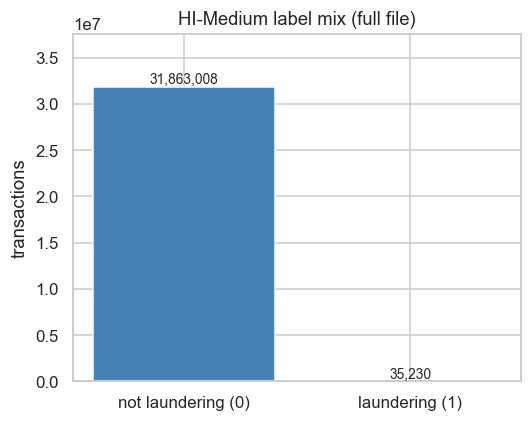


--- Dummy predictors from full-file counts ---
Accuracy always-legit: 0.998896
Accuracy always-fraud: 0.001104
Precision/recall always-legit: 0 / 0  (never predicts a positive)
Precision/recall always-fraud: 0.001104 / 1.0
AUPRC of a constant score equals prevalence ≈ 0.001104
(Use AUPRC for training; accuracy is meaningless at ~0.110% positives.)
  >> Polars scan #7 ...
  << Polars scan #7  (1.7s, 552 rows)
  >> Polars scan #8 ...
  << Polars scan #8  (0.3s, 499,448 rows)

--- sklearn on a ~500k stratified probe (EDA copy 2 style) ---
Accuracy always-legit: 0.998896
AUPRC always-legit scores (all 0.0): 0.001104
AUPRC always-fraud scores (all 1.0): 0.001104
Precision always-legit: 0.0
Precision always-fraud: 0.001104
Recall always-legit: 0.0
Recall always-fraud: 1.0


In [36]:
# --- label bar + dummy baselines (AUPRC is the metric we will train on) ---
print("Is Laundering counts:")
print(f"  0 (legit):       {n_rows - n_laundering:,}")
print(f"  1 (laundering):  {n_laundering:,}")
print(f"  full-file rate:  {full_rate*100:.4f}%   vs Kaggle 1/905 = {KAGGLE_RATE*100:.4f}%")
print("\nA 5% training subsample is an UPSAMPLE of this ~0.110% prior, not the real world rate.")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["not laundering (0)", "laundering (1)"], [n_rows - n_laundering, n_laundering], color=["steelblue", "crimson"])
ax.set_title("HI-Medium label mix (full file)")
ax.set_ylabel("transactions")
annotate_bars(ax)
plt.tight_layout()
plt.show()

# Exact count-based dummies (no full-file arrays). sklearn on a stratified probe matches EDA copy 2.
print("\n--- Dummy predictors from full-file counts ---")
print(f"Accuracy always-legit: {1 - full_rate:.6f}")
print(f"Accuracy always-fraud: {full_rate:.6f}")
print("Precision/recall always-legit: 0 / 0  (never predicts a positive)")
print(f"Precision/recall always-fraud: {full_rate:.6f} / 1.0")
print(f"AUPRC of a constant score equals prevalence ≈ {full_rate:.6f}")
print("(Use AUPRC for training; accuracy is meaningless at ~0.110% positives.)")

# Stratified probe so sklearn's AP/P/R match the EDA3 cells numerically.
probe_n = min(500_000, n_rows)
pos_n = max(1, int(probe_n * full_rate))
neg_n = probe_n - pos_n
probe = pl.concat(
    [
        collect_scan(lf_raw.filter(pl.col("Is Laundering") == 1).select("Is Laundering").head(pos_n)),
        collect_scan(lf_raw.filter(pl.col("Is Laundering") == 0).select("Is Laundering").head(neg_n)),
    ]
)
y = probe["Is Laundering"].to_numpy()
zeros = np.zeros_like(y)
ones = np.ones_like(y)
print("\n--- sklearn on a ~500k stratified probe (EDA copy 2 style) ---")
print("Accuracy always-legit:", accuracy_score(y, zeros))
print("AUPRC always-legit scores (all 0.0):", average_precision_score(y, zeros))
print("AUPRC always-fraud scores (all 1.0):", average_precision_score(y, ones))
print("Precision always-legit:", precision_score(y, zeros, zero_division=0))
print("Precision always-fraud:", precision_score(y, ones, zero_division=0))
print("Recall always-legit:", recall_score(y, zeros, zero_division=0))
print("Recall always-fraud:", recall_score(y, ones, zero_division=0))


  >> Polars scan #9 ...
  << Polars scan #9  (1.9s, 7 rows)
shape: (7, 4)
┌────────────────┬──────────┬──────────────┬──────────┐
│ Payment Format ┆ n        ┆ n_laundering ┆ rate     │
│ ---            ┆ ---      ┆ ---          ┆ ---      │
│ str            ┆ u32      ┆ i64          ┆ f64      │
╞════════════════╪══════════╪══════════════╪══════════╡
│ ACH            ┆ 3868410  ┆ 30746        ┆ 0.007948 │
│ Cheque         ┆ 12280058 ┆ 2220         ┆ 0.000181 │
│ Credit Card    ┆ 8777816  ┆ 1354         ┆ 0.000154 │
│ Cash           ┆ 3217531  ┆ 666          ┆ 0.000207 │
│ Bitcoin        ┆ 689038   ┆ 244          ┆ 0.000354 │
│ Wire           ┆ 1119774  ┆ 0            ┆ 0.0      │
│ Reinvestment   ┆ 1945611  ┆ 0            ┆ 0.0      │
└────────────────┴──────────┴──────────────┴──────────┘


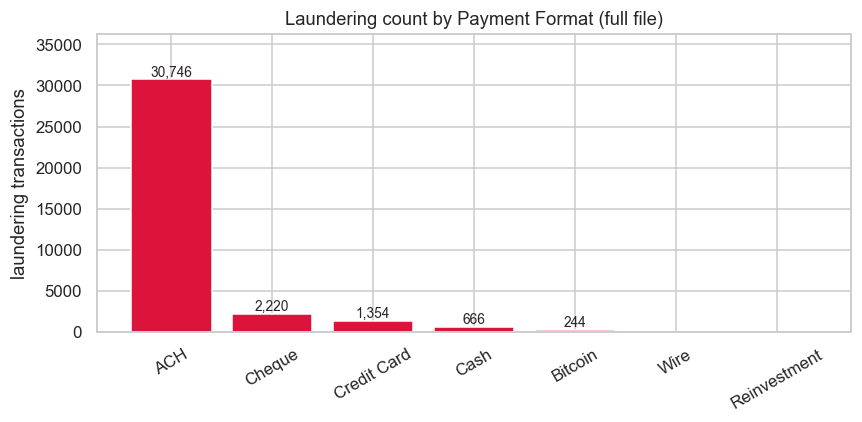

In [37]:
# --- Payment Format: IBM analogue of PaySim's fraud-by-type bar ---
fmt = collect_scan(
    lf_raw.group_by("Payment Format").agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").sum().alias("n_laundering"),
        pl.col("Is Laundering").mean().alias("rate"),
    ).sort("n_laundering", descending=True)
)
print(fmt)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(fmt["Payment Format"].to_list(), fmt["n_laundering"].to_list(), color="crimson")
ax.set_title("Laundering count by Payment Format (full file)")
ax.set_ylabel("laundering transactions")
ax.tick_params(axis="x", rotation=30)
annotate_bars(ax)
plt.tight_layout()
plt.show()


In [38]:
# --- currencies, paid vs received mismatches (FX / conversion edges) ---
print("Receiving Currency:")
print(collect_scan(lf_raw.group_by("Receiving Currency").len().sort("len", descending=True)))
print("\nPayment Currency:")
print(collect_scan(lf_raw.group_by("Payment Currency").len().sort("len", descending=True)))

mismatch = collect_scan(
    lf_raw.select(
        (pl.col("Payment Currency") != pl.col("Receiving Currency")).mean().alias("pct_cross_currency"),
        (pl.col("Amount Paid") != pl.col("Amount Received")).mean().alias("pct_amount_mismatch"),
        (
            (pl.col("Amount Paid") != pl.col("Amount Received"))
            & (pl.col("Payment Currency") == pl.col("Receiving Currency"))
        ).mean().alias("pct_mismatch_same_ccy"),
    )
)
print("\nFX / amount mismatch rates:")
print(mismatch)

print("\nSample of amount mismatches:")
display(
    collect_scan(
        lf_raw.filter(pl.col("Amount Paid") != pl.col("Amount Received"))
        .select(
            "Amount Received", "Receiving Currency",
            "Amount Paid", "Payment Currency", "Is Laundering",
        )
        .head(5)
    )
)


Receiving Currency:
  >> Polars scan #10 ...
  << Polars scan #10  (0.9s, 15 rows)
shape: (15, 2)
┌────────────────────┬──────────┐
│ Receiving Currency ┆ len      │
│ ---                ┆ ---      │
│ str                ┆ u32      │
╞════════════════════╪══════════╡
│ US Dollar          ┆ 11594241 │
│ Euro               ┆ 7329170  │
│ Yuan               ┆ 2295849  │
│ Shekel             ┆ 1428622  │
│ Canadian Dollar    ┆ 1089398  │
│ …                  ┆ …        │
│ Mexican Peso       ┆ 852272   │
│ Rupee              ┆ 741594   │
│ Bitcoin            ┆ 698372   │
│ Brazil Real        ┆ 638411   │
│ Saudi Riyal        ┆ 572750   │
└────────────────────┴──────────┘

Payment Currency:
  >> Polars scan #11 ...
  << Polars scan #11  (0.9s, 15 rows)
shape: (15, 2)
┌──────────────────┬──────────┐
│ Payment Currency ┆ len      │
│ ---              ┆ ---      │
│ str              ┆ u32      │
╞══════════════════╪══════════╡
│ US Dollar        ┆ 11688249 │
│ Euro             ┆ 7315958  │
│ Y

Amount Received,Receiving Currency,Amount Paid,Payment Currency,Is Laundering
f64,str,f64,str,i64
97.27,"""Euro""",113.98,"""US Dollar""",0
14.26,"""UK Pound""",18.42,"""US Dollar""",0
42.41,"""Euro""",49.69,"""US Dollar""",0
6707.83,"""US Dollar""",5724.46,"""Euro""",0
42.71,"""Euro""",50.05,"""US Dollar""",0


In [39]:
# --- cardinality: banks, accounts, overlap, self-transfers (Reinvestment-style loops) ---
card = collect_scan(
    lf_raw.select(
        pl.col("From Bank").n_unique().alias("n_from_bank"),
        pl.col("To Bank").n_unique().alias("n_to_bank"),
        pl.col("Account").n_unique().alias("n_account"),
        pl.col("Account.1").n_unique().alias("n_account1"),
        pl.col("Payment Format").n_unique().alias("n_format"),
        (
            (pl.col("Account") == pl.col("Account.1"))
            & (pl.col("From Bank") == pl.col("To Bank"))
        ).mean().alias("pct_self_transfer"),
        (pl.col("From Bank") != pl.col("To Bank")).mean().alias("pct_cross_bank"),
    )
)
print(card)
print(f"\nKaggle account count ~{KAGGLE_N_ACCOUNTS:,} (union of senders+receivers, not Account n_unique alone)")

# Overlap of From vs To bank IDs, Account vs Account.1.
from_banks = collect_scan(lf_raw.select(pl.col("From Bank").unique().alias("b")))
to_banks = collect_scan(lf_raw.select(pl.col("To Bank").unique().alias("b")))
bank_overlap = from_banks.join(to_banks, on="b", how="inner").height
print(
    f"Bank overlap: {bank_overlap:,}  "
    f"({100*bank_overlap/max(from_banks.height,1):.1f}% of From, "
    f"{100*bank_overlap/max(to_banks.height,1):.1f}% of To)"
)


  >> Polars scan #14 ...
  << Polars scan #14  (1.7s, 1 rows)
shape: (1, 7)
┌─────────────┬───────────┬───────────┬────────────┬──────────┬───────────────────┬────────────────┐
│ n_from_bank ┆ n_to_bank ┆ n_account ┆ n_account1 ┆ n_format ┆ pct_self_transfer ┆ pct_cross_bank │
│ ---         ┆ ---       ┆ ---       ┆ ---        ┆ ---      ┆ ---               ┆ ---            │
│ u32         ┆ u32       ┆ u32       ┆ u32        ┆ u32      ┆ f64               ┆ f64            │
╞═════════════╪═══════════╪═══════════╪════════════╪══════════╪═══════════════════╪════════════════╡
│ 122330      ┆ 62820     ┆ 2013627   ┆ 1689925    ┆ 7        ┆ 0.080314          ┆ 0.912045       │
└─────────────┴───────────┴───────────┴────────────┴──────────┴───────────────────┴────────────────┘

Kaggle account count ~2,077,000 (union of senders+receivers, not Account n_unique alone)
  >> Polars scan #15 ...
  << Polars scan #15  (0.8s, 122,330 rows)
  >> Polars scan #16 ...
  << Polars scan #16  (0.8s, 62,82

### Timestamps and the post-window artifact

Kaggle primary activity for HI-Medium is **1 Sep – 16 Sep 2022**. Marco Pianta / IBM noted that rows *after* that window exist and are **all laundering**. A chronological test split that includes that tail will look better than it is. We count it and keep it out of the 60/20/20 split later.


In [40]:
# --- parse timestamps; count the all-laundering tail after 16 Sep 2022 ---
lf_ts = lf_raw.with_columns(
    pl.col("Timestamp").str.to_datetime("%Y/%m/%d %H:%M", strict=False).alias("ts")
)
ts_span = collect_scan(
    lf_ts.select(
        pl.col("ts").min().alias("ts_min"),
        pl.col("ts").max().alias("ts_max"),
        pl.col("ts").dt.date().n_unique().alias("n_calendar_days"),
        pl.col("ts").is_null().sum().alias("n_parse_fail"),
    )
)
print(ts_span)

post = lf_ts.filter(pl.col("ts") > pl.lit(PRIMARY_END))
post_stats = collect_scan(
    post.select(
        pl.len().alias("n_post_window"),
        pl.col("Is Laundering").mean().alias("post_laundering_rate"),
        pl.col("Is Laundering").sum().alias("n_post_laundering"),
    )
)
print("\nPost-primary-window tail (expect ~100% laundering):")
print(post_stats)

in_window = lf_ts.filter(
    (pl.col("ts") >= pl.lit(PRIMARY_START)) & (pl.col("ts") <= pl.lit(PRIMARY_END))
)
win_stats = collect_scan(
    in_window.select(
        pl.len().alias("n_primary_window"),
        pl.col("Is Laundering").sum().alias("n_laundering"),
        pl.col("Is Laundering").mean().alias("rate"),
    )
)
print("\nInside primary window Sep 1 – Sep 16:")
print(win_stats)


  >> Polars scan #17 ...
  << Polars scan #17  (0.8s, 1 rows)
shape: (1, 4)
┌─────────────────────┬─────────────────────┬─────────────────┬──────────────┐
│ ts_min              ┆ ts_max              ┆ n_calendar_days ┆ n_parse_fail │
│ ---                 ┆ ---                 ┆ ---             ┆ ---          │
│ datetime[μs]        ┆ datetime[μs]        ┆ u32             ┆ u32          │
╞═════════════════════╪═════════════════════╪═════════════════╪══════════════╡
│ 2022-09-01 00:00:00 ┆ 2022-09-28 15:58:00 ┆ 28              ┆ 0            │
└─────────────────────┴─────────────────────┴─────────────────┴──────────────┘
  >> Polars scan #18 ...
  << Polars scan #18  (1.0s, 1 rows)

Post-primary-window tail (expect ~100% laundering):
shape: (1, 3)
┌───────────────┬──────────────────────┬───────────────────┐
│ n_post_window ┆ post_laundering_rate ┆ n_post_laundering │
│ ---           ┆ ---                  ┆ ---               │
│ u32           ┆ f64                  ┆ i64               

  >> Polars scan #20 ...
  << Polars scan #20  (0.1s, 1,000,000 rows)


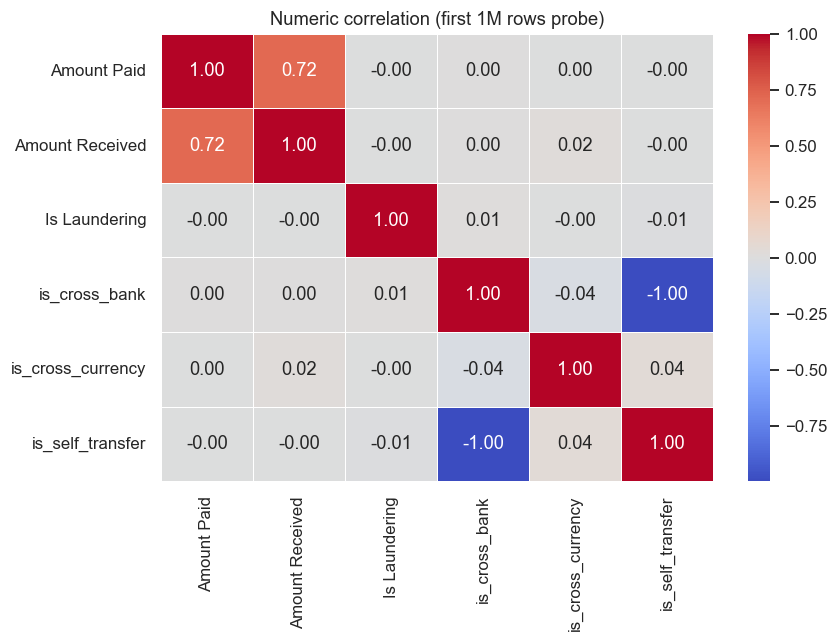

In [41]:
# --- correlation heatmap on a numeric probe (32M x N collect is unnecessary) ---
# IBM has no PaySim balances. We only correlate amounts + the label + a few flags.
corr_probe = collect_scan(
    lf_raw.select(
        "Amount Paid",
        "Amount Received",
        "Is Laundering",
        (pl.col("From Bank") != pl.col("To Bank")).cast(pl.Int8).alias("is_cross_bank"),
        (pl.col("Payment Currency") != pl.col("Receiving Currency")).cast(pl.Int8).alias("is_cross_currency"),
        (
            (pl.col("Account") == pl.col("Account.1"))
            & (pl.col("From Bank") == pl.col("To Bank"))
        ).cast(pl.Int8).alias("is_self_transfer"),
    ).head(1_000_000)
)
corr = corr_probe.to_pandas().corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Numeric correlation (first 1M rows probe)")
plt.tight_layout()
plt.show()


## 3. Fraud-pattern EDA — what concentrates laundering?

Each plot answers: **does this slice have a higher laundering *rate* than the ~0.110% prior?**
Rate (lift) matters more than raw count: Cheque can have many laundering tx simply because Cheque is common.


    stage done in 30.0s | running total 43.9s


EDA-IBM:  18%|█▊        | 2/11 stages [00:43<03:30] , 3 Fraud patterns


[3/11 | 18%] 3 Fraud patterns
shape: (7, 5)
┌────────────────┬──────────┬──────────────┬──────────┬───────────────┐
│ Payment Format ┆ n        ┆ n_laundering ┆ rate     ┆ lift_vs_prior │
│ ---            ┆ ---      ┆ ---          ┆ ---      ┆ ---           │
│ str            ┆ u32      ┆ i64          ┆ f64      ┆ f64           │
╞════════════════╪══════════╪══════════════╪══════════╪═══════════════╡
│ ACH            ┆ 3868410  ┆ 30746        ┆ 0.007948 ┆ 7.196315      │
│ Cheque         ┆ 12280058 ┆ 2220         ┆ 0.000181 ┆ 0.163684      │
│ Credit Card    ┆ 8777816  ┆ 1354         ┆ 0.000154 ┆ 0.139665      │
│ Cash           ┆ 3217531  ┆ 666          ┆ 0.000207 ┆ 0.187416      │
│ Bitcoin        ┆ 689038   ┆ 244          ┆ 0.000354 ┆ 0.320627      │
│ Wire           ┆ 1119774  ┆ 0            ┆ 0.0      ┆ 0.0           │
│ Reinvestment   ┆ 1945611  ┆ 0            ┆ 0.0      ┆ 0.0           │
└────────────────┴──────────┴──────────────┴──────────┴───────────────┘


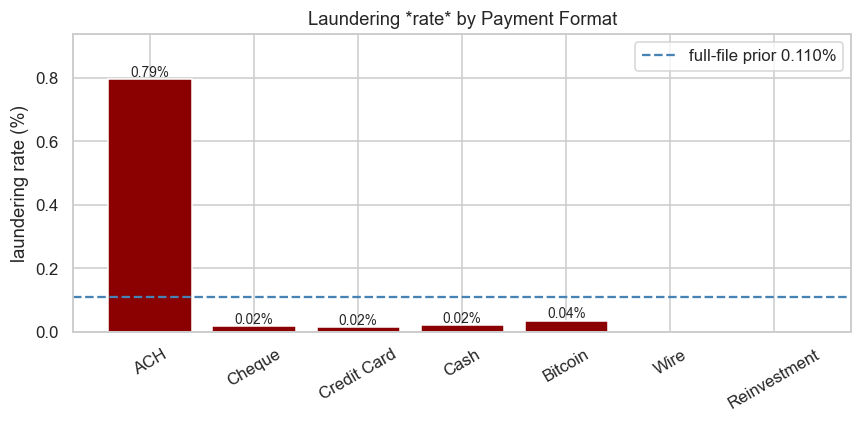

In [42]:
# --- Payment Format LIFT: rate, not just count (GNN should one-hot this) ---
pipe.section("3 Fraud patterns")
fmt = fmt.with_columns(
    (pl.col("rate") / full_rate).alias("lift_vs_prior")
)
print(fmt)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(fmt["Payment Format"].to_list(), (fmt["rate"] * 100).to_list(), color="darkred")
ax.axhline(full_rate * 100, color="steelblue", linestyle="--", label=f"full-file prior {full_rate*100:.3f}%")
ax.set_title("Laundering *rate* by Payment Format")
ax.set_ylabel("laundering rate (%)")
ax.tick_params(axis="x", rotation=30)
ax.legend()
annotate_bars(ax, as_pct=True)
plt.tight_layout()
plt.show()


  >> Polars scan #21 ...
  << Polars scan #21  (1.0s, 35,230 rows)
  >> Polars scan #22 ...
  << Polars scan #22  (0.4s, 100,000 rows)
Same-currency Amount Paid by label (probe):
shape: (2, 4)
┌───────────────┬──────────┬──────────┬───────────┐
│ Is Laundering ┆ median   ┆ mean     ┆ p90       │
│ ---           ┆ ---      ┆ ---      ┆ ---       │
│ i64           ┆ f64      ┆ f64      ┆ f64       │
╞═══════════════╪══════════╪══════════╪═══════════╡
│ 0             ┆ 2508.8   ┆ 1.0952e6 ┆ 284087.7  │
│ 1             ┆ 8668.965 ┆ 5.3117e7 ┆ 195730.33 │
└───────────────┴──────────┴──────────┴───────────┘


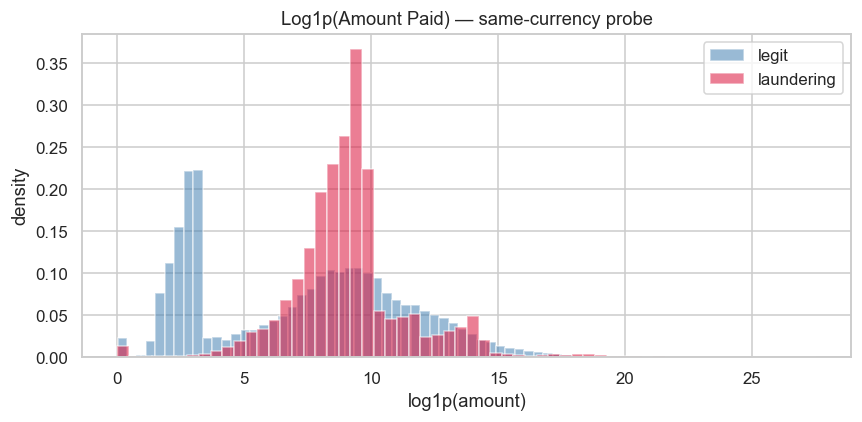

In [43]:
# --- amount shift: log-amount, laundering vs legit (stratified probe; mixed FX skipped) ---
# Full-file histograms of 32M points are unreadable. 100k per class is enough to see a shift.
n_amt = 100_000
amt_pos = collect_scan(
    same_ccy.filter(pl.col("Is Laundering") == 1)
    .select(pl.col("Amount Paid").alias("amount"), pl.col("Is Laundering"))
    .head(n_amt)
)
amt_neg = collect_scan(
    same_ccy.filter(pl.col("Is Laundering") == 0)
    .select(pl.col("Amount Paid").alias("amount"), pl.col("Is Laundering"))
    .head(n_amt)
)
amt_probe = pl.concat([amt_pos, amt_neg]).with_columns(pl.col("amount").log1p().alias("log1p_amount"))
print("Same-currency Amount Paid by label (probe):")
print(amt_probe.group_by("Is Laundering").agg(
    pl.col("amount").median().alias("median"),
    pl.col("amount").mean().alias("mean"),
    pl.col("amount").quantile(0.9).alias("p90"),
))

fig, ax = plt.subplots(figsize=(8, 4))
for lab, color, name in [(0, "steelblue", "legit"), (1, "crimson", "laundering")]:
    vals = amt_probe.filter(pl.col("Is Laundering") == lab)["log1p_amount"].to_numpy()
    ax.hist(vals, bins=60, alpha=0.55, color=color, label=name, density=True)
ax.set_title("Log1p(Amount Paid) — same-currency probe")
ax.set_xlabel("log1p(amount)")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()
plt.show()


In [44]:
# --- FX / cross-currency and paid≠received: do conversion edges hide funds? ---
fx = collect_scan(
    lf_raw.group_by(
        (pl.col("Payment Currency") != pl.col("Receiving Currency")).alias("is_cross_currency")
    ).agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").mean().alias("rate"),
    ).sort("is_cross_currency")
)
mismatch_rate = collect_scan(
    lf_raw.group_by(
        (pl.col("Amount Paid") != pl.col("Amount Received")).alias("amount_mismatch")
    ).agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").mean().alias("rate"),
    ).sort("amount_mismatch")
)
print("Cross-currency vs same-currency:")
print(fx.with_columns((pl.col("rate") / full_rate).alias("lift")))
print("\nPaid ≠ Received:")
print(mismatch_rate.with_columns((pl.col("rate") / full_rate).alias("lift")))


  >> Polars scan #23 ...
  << Polars scan #23  (1.1s, 2 rows)
  >> Polars scan #24 ...
  << Polars scan #24  (1.1s, 2 rows)
Cross-currency vs same-currency:
shape: (2, 4)
┌───────────────────┬──────────┬──────────┬──────────┐
│ is_cross_currency ┆ n        ┆ rate     ┆ lift     │
│ ---               ┆ ---      ┆ ---      ┆ ---      │
│ bool              ┆ u32      ┆ f64      ┆ f64      │
╞═══════════════════╪══════════╪══════════╪══════════╡
│ false             ┆ 31413094 ┆ 0.001122 ┆ 1.015444 │
│ true              ┆ 485144   ┆ 0.0      ┆ 0.0      │
└───────────────────┴──────────┴──────────┴──────────┘

Paid ≠ Received:
shape: (2, 4)
┌─────────────────┬──────────┬──────────┬──────────┐
│ amount_mismatch ┆ n        ┆ rate     ┆ lift     │
│ ---             ┆ ---      ┆ ---      ┆ ---      │
│ bool            ┆ u32      ┆ f64      ┆ f64      │
╞═════════════════╪══════════╪══════════╪══════════╡
│ false           ┆ 31413151 ┆ 0.001122 ┆ 1.015442 │
│ true            ┆ 485087   ┆ 0.0     

  >> Polars scan #25 ...
  << Polars scan #25  (1.1s, 2 rows)
Intra-bank vs cross-bank:
shape: (2, 5)
┌───────────────┬──────────┬──────────────┬──────────┬──────────┐
│ is_cross_bank ┆ n        ┆ n_laundering ┆ rate     ┆ lift     │
│ ---           ┆ ---      ┆ ---          ┆ ---      ┆ ---      │
│ bool          ┆ u32      ┆ i64          ┆ f64      ┆ f64      │
╞═══════════════╪══════════╪══════════════╪══════════╪══════════╡
│ false         ┆ 2805614  ┆ 343          ┆ 0.000122 ┆ 0.110693 │
│ true          ┆ 29092624 ┆ 34887        ┆ 0.001199 ┆ 1.085762 │
└───────────────┴──────────┴──────────────┴──────────┴──────────┘
  >> Polars scan #26 ...
  << Polars scan #26  (1.1s, 15 rows)

Top From Banks by laundering rate (n >= 10,000):
shape: (15, 3)
┌───────────┬───────┬──────────┐
│ From Bank ┆ n     ┆ rate     │
│ ---       ┆ ---   ┆ ---      │
│ i64       ┆ u32   ┆ f64      │
╞═══════════╪═══════╪══════════╡
│ 272142    ┆ 16169 ┆ 0.008844 │
│ 9340      ┆ 16747 ┆ 0.00406  │
│ 272896   

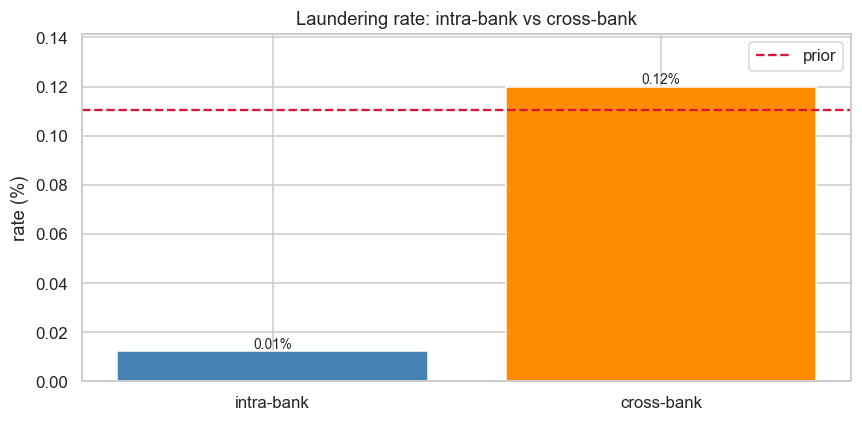

In [45]:
# --- intra-bank vs cross-bank, and banks with elevated laundering rate ---
# A real bank only sees its own slice; this dataset sees every institution (Kaggle writeup).
bank_dir = collect_scan(
    lf_raw.group_by((pl.col("From Bank") != pl.col("To Bank")).alias("is_cross_bank")).agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").sum().alias("n_laundering"),
        pl.col("Is Laundering").mean().alias("rate"),
    ).sort("is_cross_bank")
)
print("Intra-bank vs cross-bank:")
print(bank_dir.with_columns((pl.col("rate") / full_rate).alias("lift")))

MIN_BANK_TX = 10_000  # ignore tiny banks so rare-event rates do not dominate
from_bank = collect_scan(
    lf_raw.group_by("From Bank").agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").mean().alias("rate"),
    )
    .filter(pl.col("n") >= MIN_BANK_TX)
    .sort("rate", descending=True)
    .head(15)
)
print(f"\nTop From Banks by laundering rate (n >= {MIN_BANK_TX:,}):")
print(from_bank)

fig, ax = plt.subplots(figsize=(8, 4))
labels = ["intra-bank" if not v else "cross-bank" for v in bank_dir["is_cross_bank"].to_list()]
ax.bar(labels, (bank_dir["rate"] * 100).to_list(), color=["steelblue", "darkorange"])
ax.axhline(full_rate * 100, color="crimson", linestyle="--", label="prior")
ax.set_title("Laundering rate: intra-bank vs cross-bank")
ax.set_ylabel("rate (%)")
ax.legend()
annotate_bars(ax, as_pct=True)
plt.tight_layout()
plt.show()


  >> Polars scan #27 ...
  << Polars scan #27  (1.0s, 24 rows)
  >> Polars scan #28 ...
  << Polars scan #28  (1.1s, 7 rows)


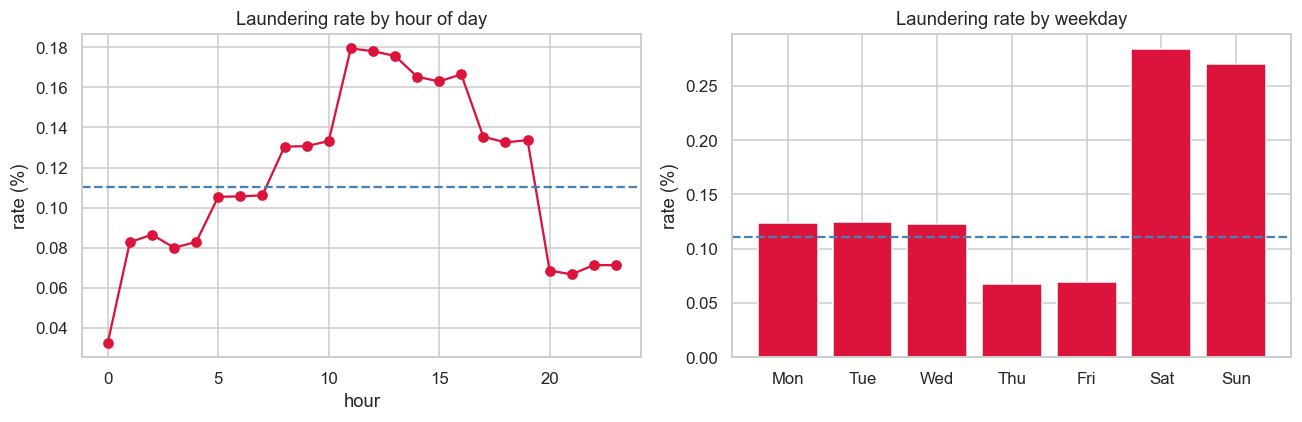

  >> Polars scan #29 ...
  << Polars scan #29  (1.1s, 28 rows)


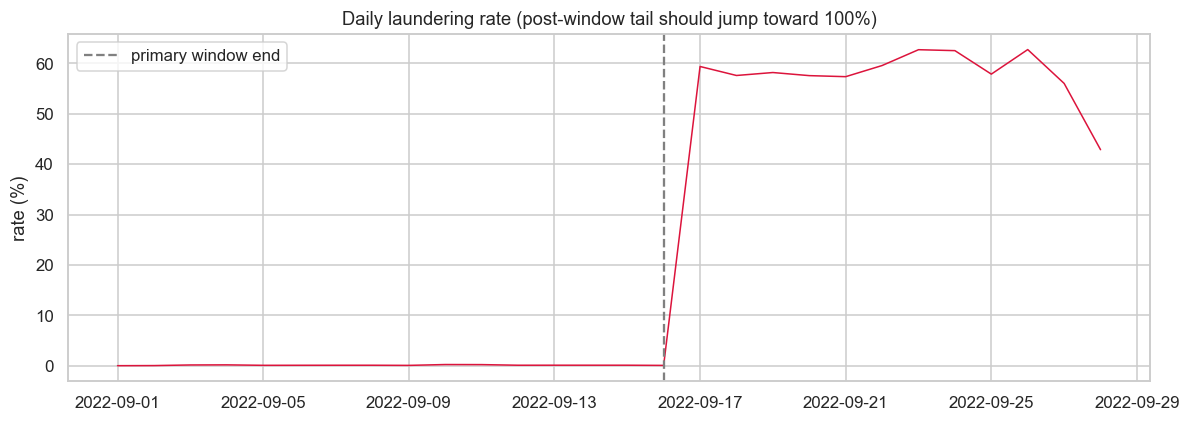

In [46]:
# --- time patterns: hour-of-day, day-of-week, daily rate (rings are often bursty) ---
time_df = collect_scan(
    lf_ts.group_by(pl.col("ts").dt.hour().alias("hour")).agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").mean().alias("rate"),
    ).sort("hour")
)
dow = collect_scan(
    lf_ts.group_by(pl.col("ts").dt.weekday().alias("dow")).agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").mean().alias("rate"),
    ).sort("dow")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(time_df["hour"], time_df["rate"] * 100, marker="o", color="crimson")
axes[0].axhline(full_rate * 100, linestyle="--", color="steelblue")
axes[0].set_title("Laundering rate by hour of day")
axes[0].set_xlabel("hour")
axes[0].set_ylabel("rate (%)")

dow_names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
axes[1].bar(
    [dow_names.get(int(d), str(d)) for d in dow["dow"].to_list()],
    (dow["rate"] * 100).to_list(),
    color="crimson",
)
axes[1].axhline(full_rate * 100, linestyle="--", color="steelblue")
axes[1].set_title("Laundering rate by weekday")
axes[1].set_ylabel("rate (%)")
plt.tight_layout()
plt.show()

# Daily rate inside the primary window — watch for a spike after Sep 16 if included.
daily = collect_scan(
    lf_ts.group_by(pl.col("ts").dt.date().alias("day")).agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").sum().alias("n_laundering"),
        pl.col("Is Laundering").mean().alias("rate"),
    ).sort("day")
)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily["day"].to_list(), (daily["rate"] * 100).to_list(), color="crimson", linewidth=1)
ax.axvline(PRIMARY_END.date(), color="gray", linestyle="--", label="primary window end")
ax.set_title("Daily laundering rate (post-window tail should jump toward 100%)")
ax.set_ylabel("rate (%)")
ax.legend()
plt.tight_layout()
plt.show()


In [47]:
# --- self-transfers (same account+bank both sides): Reinvestment / loops for a GNN ---
self_stats = collect_scan(
    lf_raw.group_by(
        (
            (pl.col("Account") == pl.col("Account.1"))
            & (pl.col("From Bank") == pl.col("To Bank"))
        ).alias("is_self_transfer")
    ).agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").mean().alias("rate"),
    ).sort("is_self_transfer")
)
print(self_stats.with_columns((pl.col("rate") / full_rate).alias("lift")))

reinv = collect_scan(
    lf_raw.group_by((pl.col("Payment Format") == "Reinvestment").alias("is_reinvestment")).agg(
        pl.len().alias("n"),
        pl.col("Is Laundering").mean().alias("rate"),
    )
)
print("\nReinvestment format vs other:")
print(reinv.with_columns((pl.col("rate") / full_rate).alias("lift")))


  >> Polars scan #30 ...
  << Polars scan #30  (1.1s, 2 rows)
shape: (2, 4)
┌──────────────────┬──────────┬──────────┬──────────┐
│ is_self_transfer ┆ n        ┆ rate     ┆ lift     │
│ ---              ┆ ---      ┆ ---      ┆ ---      │
│ bool             ┆ u32      ┆ f64      ┆ f64      │
╞══════════════════╪══════════╪══════════╪══════════╡
│ false            ┆ 29336378 ┆ 0.001198 ┆ 1.085105 │
│ true             ┆ 2561860  ┆ 0.000028 ┆ 0.025447 │
└──────────────────┴──────────┴──────────┴──────────┘
  >> Polars scan #31 ...
  << Polars scan #31  (1.2s, 2 rows)

Reinvestment format vs other:
shape: (2, 4)
┌─────────────────┬──────────┬──────────┬──────────┐
│ is_reinvestment ┆ n        ┆ rate     ┆ lift     │
│ ---             ┆ ---      ┆ ---      ┆ ---      │
│ bool            ┆ u32      ┆ f64      ┆ f64      │
╞═════════════════╪══════════╪══════════╪══════════╡
│ true            ┆ 1945611  ┆ 0.0      ┆ 0.0      │
│ false           ┆ 29952627 ┆ 0.001176 ┆ 1.064956 │
└─────────────

Fan-in / fan-out, repeat pairs, and neighborhood homophily need an in-memory graph, so they run **after** the subsample (section 5). Mule-ring *sizes* are section 7.

**Signals worth encoding so far (full file):**
- `Payment Format` (rate lift, not just count)
- amount (shift on log scale)
- `is_cross_bank`, `is_cross_currency`
- time (`hours_from_start`, possibly hour-of-day)
- `is_self_transfer` (keep self-loops; do not drop Reinvestment)


## 4. Cleaning for a GNN

Build graph fields on the lazy frame:

- **Node IDs:** `sender_id` = `Account` + `From Bank`, `receiver_id` = `Account.1` + `To Bank` (same as `main.ipynb` — account numbers can collide across banks)
- **Time:** parsed `ts`, later `hours_from_start`
- **Amount:** mid of paid/received after static AUD conversion (`main.ipynb` rates)
- **Flags:** self-transfer, cross-bank, cross-currency

We do **not** drop `Payment Format` — it becomes one-hot edge features on the subsample.


In [48]:
# --- attach GNN fields to the lazy scan (still not materializing 32M rows) ---
pipe.section("4 Cleaning")

def dest_account_col(names):
    """Polars may keep CSV 'Account.1' or rename the 2nd Account column to Account_duplicated_0."""
    for name in ("Account.1", "Account_duplicated_0", "Account_right"):
        if name in names:
            return name
    raise KeyError(
        "Could not find destination account column. Schema names: " + ", ".join(names)
    )


def with_graph_fields(lazy: pl.LazyFrame) -> pl.LazyFrame:
    """Composite node IDs, timestamps, AUD amounts, and AML flags."""
    names = list(lazy.collect_schema().names())
    dest_col = dest_account_col(names)
    print(f"Destination account column: {dest_col!r}")
    return (
        lazy.with_columns(
            pl.col("From Bank").cast(pl.Utf8),
            pl.col("To Bank").cast(pl.Utf8),
            pl.col("Account").cast(pl.Utf8),
            pl.col(dest_col).cast(pl.Utf8).alias("_dest_acct"),
        )
        .with_columns(
            (pl.col("Account") + "_" + pl.col("From Bank")).alias("sender_id"),
            (pl.col("_dest_acct") + "_" + pl.col("To Bank")).alias("receiver_id"),
            pl.col("Timestamp").str.to_datetime("%Y/%m/%d %H:%M", strict=False).alias("ts"),
            (
                pl.col("Amount Paid")
                * pl.col("Payment Currency").replace_strict(RATES, default=1.0)
            ).alias("amount_paid_aud"),
            (
                pl.col("Amount Received")
                * pl.col("Receiving Currency").replace_strict(RATES, default=1.0)
            ).alias("amount_received_aud"),
        )
        .with_columns(
            ((pl.col("amount_paid_aud") + pl.col("amount_received_aud")) / 2).alias("amount"),
            (pl.col("sender_id") == pl.col("receiver_id")).cast(pl.Int8).alias("is_self_transfer"),
            (pl.col("From Bank") != pl.col("To Bank")).cast(pl.Int8).alias("is_cross_bank"),
            (pl.col("Payment Currency") != pl.col("Receiving Currency")).cast(pl.Int8).alias("is_cross_currency"),
        )
    )


lf = with_graph_fields(lf_raw)
print("Graph-field schema:")
print(lf.collect_schema())
print("\nPreview with IDs + flags:")
display(
    collect_scan(
        lf.select(
            "ts", "sender_id", "receiver_id", "amount",
            "Payment Format", "is_self_transfer", "is_cross_bank", "is_cross_currency",
            "Is Laundering",
        ).head(5)
    )
)


    stage done in 11.8s | running total 55.7s


EDA-IBM:  27%|██▋       | 3/11 stages [00:55<02:24] , 4 Cleaning      


[4/11 | 27%] 4 Cleaning
Destination account column: 'Account.1'
Graph-field schema:
Schema([('Timestamp', String), ('From Bank', String), ('Account', String), ('To Bank', String), ('Account.1', String), ('Amount Received', Float64), ('Receiving Currency', String), ('Amount Paid', Float64), ('Payment Currency', String), ('Payment Format', String), ('Is Laundering', Int64), ('_dest_acct', String), ('sender_id', String), ('receiver_id', String), ('ts', Datetime(time_unit='us', time_zone=None)), ('amount_paid_aud', Float64), ('amount_received_aud', Float64), ('amount', Float64), ('is_self_transfer', Int8), ('is_cross_bank', Int8), ('is_cross_currency', Int8)])

Preview with IDs + flags:
  >> Polars scan #32 ...
  << Polars scan #32  (0.0s, 5 rows)


ts,sender_id,receiver_id,amount,Payment Format,is_self_transfer,is_cross_bank,is_cross_currency,Is Laundering
datetime[μs],str,str,f64,str,i8,i8,i8,i64
2022-09-01 00:17:00,"""800104D70_20""","""800104D70_20""",9512.482,"""Reinvestment""",1,0,0,0
2022-09-01 00:02:00,"""800107150_3196""","""800107150_3196""",10835.006,"""Reinvestment""",1,0,0,0
2022-09-01 00:17:00,"""80010E430_1208""","""80010E430_1208""",2632.322,"""Reinvestment""",1,0,0,0
2022-09-01 00:03:00,"""80010E650_1208""","""80010E6F0_20""",1.0355e8,"""Cheque""",0,1,0,0
2022-09-01 00:02:00,"""80010E650_1208""","""80010EA30_20""",6.4216e7,"""Cheque""",0,1,0,0


## 5. Neighborhood subsample: 750k minimum, 5% by formula

Keep **every** laundering edge (mule rings stay whole). Size the sample with:

```
n_total = max(MIN_ROWS, round(n_fraud / MIN_FRAUD_RATE))
n_legit = n_total - n_fraud
```

With ~35K laundering, `n_fraud / 0.05 ≈ 700K`, which is below the 750K floor. We **do not pad to 750K** because that would drop the mix under 5%. Result: **~700K rows at 5%**.

Legit rows are filled **neighborhood-first** (k-hop around laundering accounts, same idea as EDA3) then random background. That is the “camouflage” IBM describes: illicit funds mixed into ordinary traffic.

If `ibm_hi_medium_sample.parquet` exists, we load it and skip the 32M walk.


In [49]:
# --- k-hop neighborhood subsample with a hard 5% floor and 750k minimum ---
pipe.section("5 Subsample (slowest)")
def accounts_frame(df: pl.DataFrame) -> pl.DataFrame:
    return pl.concat(
        [
            df.select(pl.col("sender_id").alias("account")),
            df.select(pl.col("receiver_id").alias("account")),
        ]
    ).unique()


def expand_account_pool(lazy_all: pl.LazyFrame, seed_accounts: pl.DataFrame, max_hops: int):
    """Grow the account set hop by hop via joins (no giant Python is_in lists)."""
    pool = seed_accounts.unique()
    hop_sizes = [pool.height]
    print(f"0-hop (laundering) accounts: {pool.height:,}")
    nonfraud = lazy_all.filter(pl.col("Is Laundering") == 0)
    used_hops = 0
    hop_bar = tqdm(range(1, max_hops), desc="Hop expansion", unit="hop", leave=True)
    for hop in hop_bar:
        hop_bar.set_postfix_str(f"pool={pool.height:,}")
        pool_l = pool.lazy()
        via_src = (
            nonfraud.join(pool_l, left_on="sender_id", right_on="account", how="semi")
            .select(pl.col("receiver_id").alias("account"))
        )
        via_dst = (
            nonfraud.join(pool_l, left_on="receiver_id", right_on="account", how="semi")
            .select(pl.col("sender_id").alias("account"))
        )
        new_accts = collect_scan(
            pl.concat([via_src, via_dst]).unique(),
            desc=f"hop {hop} account expansion (full-file join)",
        )
        pool = pl.concat([pool, new_accts]).unique()
        hop_sizes.append(pool.height)
        used_hops = hop
        hop_bar.set_postfix_str(f"pool={pool.height:,}")
        print(f"Hop {hop} pool size: {pool.height:,} unique accounts")
        if pool.height >= MAX_POOL_ACCOUNTS:
            print("Account-pool cap hit — stopping expansion (4 hops would swallow HI-Medium).")
            break
    hop_bar.close()
    return pool, hop_sizes, used_hops


def hash_sample(lazy: pl.LazyFrame, n: int, seed: int) -> pl.DataFrame:
    """Approximate sample of n rows from a huge lazy frame without collecting all of it."""
    if n <= 0:
        return collect_scan(lazy.head(0))
    n_avail = int(collect_scan(lazy.select(pl.len()), desc="count rows before hash-sample").item())
    if n_avail == 0:
        return collect_scan(lazy.head(0), desc="empty hash-sample")
    if n_avail <= n:
        return collect_scan(lazy, desc=f"collect all {n_avail:,} hash-sample candidates")
    # Keep a hash bucket slightly larger than n, then exact-sample down.
    keep = min(1_000_000, max(1, int(1_000_000 * (n * 1.4) / n_avail) + 1))
    over = collect_scan(
        lazy.with_columns((pl.col("sender_id").hash(seed=seed) % 1_000_000).alias("_b"))
        .filter(pl.col("_b") < keep)
        .drop("_b")
    )
    if over.height >= n:
        return over.sample(n=n, seed=seed)
    # Undershot the hash — collect a bit more with a second seed, then trim.
    extra = collect_scan(
        lazy.with_columns((pl.col("receiver_id").hash(seed=seed + 1) % 1_000_000).alias("_b"))
        .filter(pl.col("_b") < keep)
        .drop("_b")
    )
    merged = pl.concat([over, extra]).unique()
    if merged.height >= n:
        return merged.sample(n=n, seed=seed)
    return merged


def sample_gnn_neighborhood(lazy: pl.LazyFrame):
    print("=== Subsample formula ===")
    print(f"MIN_ROWS        = {MIN_ROWS:,}")
    print(f"MIN_FRAUD_RATE  = {MIN_FRAUD_RATE:.2%}")
    print()

    fraud = collect_scan(lazy.filter(pl.col("Is Laundering") == 1), desc="collect ALL laundering rows")
    n_fraud = fraud.height
    n_total_5pct = int(round(n_fraud / MIN_FRAUD_RATE))
    n_total = max(MIN_ROWS, n_total_5pct)
    # HI-Medium has ~35K positives: 750k rows would be ~4.7% laundering. Prefer the 5% floor.
    if n_fraud / n_total < MIN_FRAUD_RATE:
        print(
            f"NOTE: max({MIN_ROWS:,}, {n_total_5pct:,}) = {n_total:,} would be "
            f"{n_fraud / n_total:.2%} laundering (< {MIN_FRAUD_RATE:.0%}). "
            f"Using {n_total_5pct:,} rows so the mix stays at 5%."
        )
        n_total = n_total_5pct
    n_legit = n_total - n_fraud
    print(f"n_fraud (keep all)     = {n_fraud:,}")
    print(f"n_fraud / 0.05         = {n_total_5pct:,}   (size that makes the rate exactly 5%)")
    print(f"n_total                = {n_total:,}")
    print(f"n_legit                = {n_legit:,}")
    print(f"full-file rate         = {full_rate*100:.4f}%")
    print(f"target subsample rate  = {n_fraud / n_total:.4%}")
    print()

    seed_accts = accounts_frame(fraud)
    pool, hop_sizes, used_hops = expand_account_pool(lazy, seed_accts, MAX_HOPS)
    accts = pool.get_column("account")

    nonfraud = lazy.filter(pl.col("Is Laundering") == 0)
    neigh_lf = nonfraud.filter(
        pl.col("sender_id").is_in(accts) | pl.col("receiver_id").is_in(accts)
    )
    rest_lf = nonfraud.filter(
        ~(pl.col("sender_id").is_in(accts) | pl.col("receiver_id").is_in(accts))
    )

    n_neigh_avail = int(collect_scan(neigh_lf.select(pl.len()), desc="count neighborhood legit").item())
    print(f"Neighborhood legit available: {n_neigh_avail:,}")
    n_neigh_keep = min(n_neigh_avail, n_legit)
    n_rest_keep = n_legit - n_neigh_keep
    print(f"Keeping neighborhood legit:   {n_neigh_keep:,}")
    print(f"Filling random legit:         {n_rest_keep:,}")

    neigh_s = hash_sample(neigh_lf, n_neigh_keep, RANDOM_STATE).with_columns(
        pl.lit("neighborhood").alias("sample_source")
    )
    rest_s = hash_sample(rest_lf, n_rest_keep, RANDOM_STATE + 7).with_columns(
        pl.lit("random").alias("sample_source")
    )
    fraud_s = fraud.with_columns(pl.lit("laundering").alias("sample_source"))

    sampled = pl.concat([fraud_s, neigh_s, rest_s], how="diagonal_relaxed").sample(
        fraction=1.0, seed=RANDOM_STATE
    )
    rate = sampled["Is Laundering"].mean()
    print()
    print(f"Final subsample: {sampled.height:,} rows")
    print(f"  laundering: {int(sampled['Is Laundering'].sum()):,}")
    print(f"  legit:      {int((sampled['Is Laundering'] == 0).sum()):,}")
    print(f"  rate:       {rate:.4%}   (full-file was {full_rate:.4%})")
    if sampled.height < MIN_ROWS:
        print(f"NOTE: {sampled.height:,} rows < {MIN_ROWS:,} minimum — 5% floor won over the 750k pad.")
    assert rate >= MIN_FRAUD_RATE - 1e-6, "subsample fell below 5% laundering"
    return sampled, neigh_s.height, rest_s.height, hop_sizes, used_hops


if SAMPLE_PATH.exists():
    print(f"Found {SAMPLE_PATH.resolve()} — loading cached subsample.")
    df_sampled = pl.read_parquet(SAMPLE_PATH)
    if "sample_source" not in df_sampled.columns:
        df_sampled = df_sampled.with_columns(
            pl.when(pl.col("Is Laundering") == 1)
            .then(pl.lit("laundering"))
            .otherwise(pl.lit("unknown"))
            .alias("sample_source")
        )
    n_fraud_s = int(df_sampled["Is Laundering"].sum())
    n_neigh_s = df_sampled.filter(pl.col("sample_source") == "neighborhood").height
    n_rest_s = df_sampled.filter(pl.col("sample_source") == "random").height
    hop_sizes, used_hops = [], None
    print(df_sampled.shape, "rate", f"{df_sampled['Is Laundering'].mean():.4%}")
else:
    df_sampled, n_neigh_s, n_rest_s, hop_sizes, used_hops = sample_gnn_neighborhood(lf)
    n_fraud_s = int(df_sampled["Is Laundering"].sum())
    df_sampled.write_parquet(SAMPLE_PATH)
    print(f"\nWrote {SAMPLE_PATH.resolve()}")

# hours_from_start on the sample (t0 = first timestamp in this table)
t0 = df_sampled["ts"].min()
df_sampled = df_sampled.with_columns(
    ((pl.col("ts") - t0).dt.total_seconds() / 3600.0).alias("hours_from_start")
)

rate_s = float(df_sampled["Is Laundering"].mean())
print(f"\nASSERTS: n={df_sampled.height:,}  rate={rate_s:.4%} (>= {MIN_FRAUD_RATE:.2%})")


    stage done in 0.1s | running total 55.7s


EDA-IBM:  36%|███▋      | 4/11 stages [00:55<02:06] , 5 Subsample (slowest)


[5/11 | 36%] 5 Subsample (slowest)
Found /Users/wesley/Desktop/Capstone dataset/ibm_hi_medium_sample.parquet — loading cached subsample.
(704600, 21) rate 5.0000%

ASSERTS: n=704,600  rate=5.0000% (>= 5.00%)


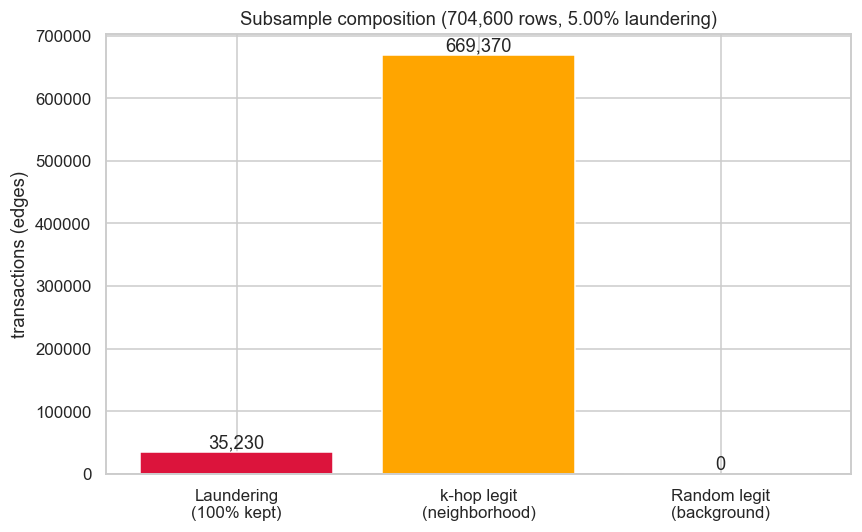

Formula recap: n_total_5pct = round(35,230 / 0.05) = 704,600; emitted 704,600 rows at 5.00%


In [50]:
# --- composition bar: how we filled the sample (EDA3 style) ---
n_fraud_s = int(df_sampled["Is Laundering"].sum())
if "sample_source" in df_sampled.columns:
    n_neigh_s = df_sampled.filter(pl.col("sample_source") == "neighborhood").height
    n_rest_s = df_sampled.filter(pl.col("sample_source") == "random").height
composition_counts = [n_fraud_s, n_neigh_s, n_rest_s]
composition_labels = [
    "Laundering\n(100% kept)",
    "k-hop legit\n(neighborhood)",
    "Random legit\n(background)",
]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(composition_labels, composition_counts, color=["crimson", "orange", "steelblue"])
ax.set_title(f"Subsample composition ({df_sampled.height:,} rows, {rate_s*100:.2f}% laundering)")
ax.set_ylabel("transactions (edges)")
ax.axhline(0, color="black", linewidth=0.5)
for bar, val in zip(bars, composition_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, val, f"{int(val):,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(
    f"Formula recap: n_total_5pct = round({n_fraud_s:,} / {MIN_FRAUD_RATE}) "
    f"= {int(round(n_fraud_s / MIN_FRAUD_RATE)):,}; "
    f"emitted {df_sampled.height:,} rows at {rate_s:.2%}"
)
if hop_sizes:
    print("Hop pool sizes:", hop_sizes)


### Fan-in / fan-out, repeat pairs, homophily (on the subsample)

These are the graph reasons a GNN can beat a tabular model: mules look like ordinary accounts until you see **who they are connected to**.


Degree by whether the account touches a laundering edge:
shape: (2, 7)
┌────────────────────┬────────────┬───────────┬────────────┬─────────────┬────────┬─────────┐
│ touches_laundering ┆ n_accounts ┆ median_in ┆ median_out ┆ mean_degree ┆ p90_in ┆ p90_out │
│ ---                ┆ ---        ┆ ---       ┆ ---        ┆ ---         ┆ ---    ┆ ---     │
│ bool               ┆ u32        ┆ f64       ┆ f64        ┆ f64         ┆ f64    ┆ f64     │
╞════════════════════╪════════════╪═══════════╪════════════╪═════════════╪════════╪═════════╡
│ false              ┆ 120899     ┆ 3.0       ┆ 0.0        ┆ 7.450351    ┆ 13.0   ┆ 5.0     │
│ true               ┆ 41857      ┆ 1.0       ┆ 1.0        ┆ 12.14755    ┆ 3.0    ┆ 1.0     │
└────────────────────┴────────────┴───────────┴────────────┴─────────────┴────────┴─────────┘

Heuristic fan-in accounts:  39,464  (touch laundering: 2,482)
Heuristic fan-out accounts: 9,809  (touch laundering: 570)
Heuristic mule accounts:    2,136  (touch laundering: 6

/var/folders/85/tw01mlpj2652rq0cxftdtsvw0000gn/T/ipykernel_46170/2166791248.py:9: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  out_deg.rename({"sender_id": "id"})


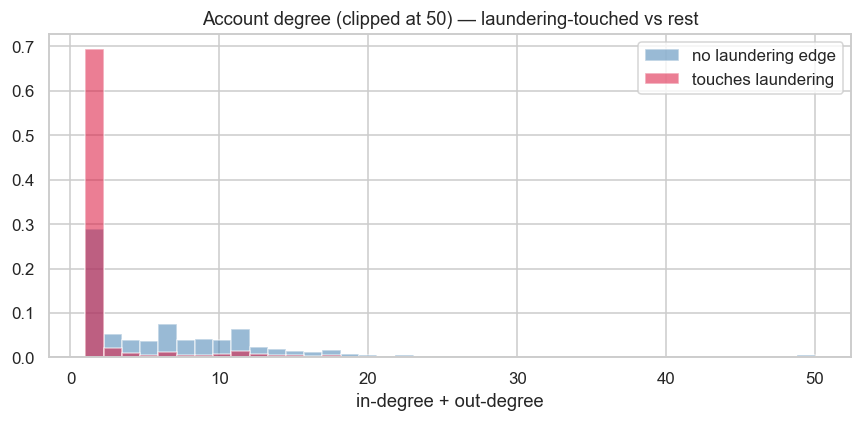

In [51]:
# --- degree / pair / homophily signals on the subsample graph ---
out_deg = df_sampled.group_by("sender_id").agg(pl.len().alias("out_degree"))
in_deg = df_sampled.group_by("receiver_id").agg(pl.len().alias("in_degree"))

fraud_accts = accounts_frame(df_sampled.filter(pl.col("Is Laundering") == 1)).rename(
    {"account": "id"}
)
node_deg = (
    out_deg.rename({"sender_id": "id"})
    .join(in_deg.rename({"receiver_id": "id"}), on="id", how="full", coalesce=True)
    .with_columns(pl.col("out_degree").fill_null(0), pl.col("in_degree").fill_null(0))
    .with_columns((pl.col("in_degree") + pl.col("out_degree")).alias("degree"))
    .with_columns(pl.col("id").is_in(fraud_accts.get_column("id")).alias("touches_laundering"))
)

print("Degree by whether the account touches a laundering edge:")
print(
    node_deg.group_by("touches_laundering").agg(
        pl.len().alias("n_accounts"),
        pl.col("in_degree").median().alias("median_in"),
        pl.col("out_degree").median().alias("median_out"),
        pl.col("degree").mean().alias("mean_degree"),
        pl.col("in_degree").quantile(0.9).alias("p90_in"),
        pl.col("out_degree").quantile(0.9).alias("p90_out"),
    )
)

# Fan-in suspects: high in, low out (collectors). Fan-out: high out, low in (distributors).
fan_in = node_deg.filter((pl.col("in_degree") >= 8) & (pl.col("out_degree") <= 2))
fan_out = node_deg.filter((pl.col("out_degree") >= 8) & (pl.col("in_degree") <= 2))
mules = node_deg.filter((pl.col("in_degree") >= 3) & (pl.col("out_degree") >= 3))
print(f"\nHeuristic fan-in accounts:  {fan_in.height:,}  (touch laundering: {int(fan_in['touches_laundering'].sum()):,})")
print(f"Heuristic fan-out accounts: {fan_out.height:,}  (touch laundering: {int(fan_out['touches_laundering'].sum()):,})")
print(f"Heuristic mule accounts:    {mules.height:,}  (touch laundering: {int(mules['touches_laundering'].sum()):,})")

fig, ax = plt.subplots(figsize=(8, 4))
for flag, color, name in [(False, "steelblue", "no laundering edge"), (True, "crimson", "touches laundering")]:
    vals = node_deg.filter(pl.col("touches_laundering") == flag)["degree"].clip(upper_bound=50).to_numpy()
    ax.hist(vals, bins=40, alpha=0.55, color=color, label=name, density=True)
ax.set_title("Account degree (clipped at 50) — laundering-touched vs rest")
ax.set_xlabel("in-degree + out-degree")
ax.legend()
plt.tight_layout()
plt.show()


In [52]:
# --- repeat (sender, receiver) pairs: multi-edges in the directed multigraph ---
pairs = (
    df_sampled.group_by(["sender_id", "receiver_id"])
    .agg(
        pl.len().alias("n_tx"),
        pl.col("Is Laundering").mean().alias("laundering_rate"),
        pl.col("Is Laundering").sum().alias("n_laundering"),
    )
    .sort("n_tx", descending=True)
)
print("Pair multiplicity:")
print(
    pairs.select(
        pl.len().alias("n_unique_pairs"),
        (pl.col("n_tx") > 1).mean().alias("pct_pairs_with_repeats"),
        pl.col("n_tx").max().alias("max_tx_on_one_pair"),
    )
)
print("\nLaundering rate vs how often the same pair transacts:")
print(
    pairs.group_by(
        pl.when(pl.col("n_tx") == 1).then(pl.lit("1"))
        .when(pl.col("n_tx") <= 3).then(pl.lit("2-3"))
        .when(pl.col("n_tx") <= 10).then(pl.lit("4-10"))
        .otherwise(pl.lit("11+"))
        .alias("multiplicity")
    ).agg(
        pl.len().alias("n_pairs"),
        pl.col("laundering_rate").mean().alias("mean_pair_rate"),
        pl.col("n_laundering").sum().alias("n_laundering"),
    ).sort("multiplicity")
)

# Homophily: among accounts that already touch laundering, what fraction of *their* edges are laundering?
touch_ids = fraud_accts.get_column("id")
touch_edges = df_sampled.filter(
    pl.col("sender_id").is_in(touch_ids) | pl.col("receiver_id").is_in(touch_ids)
)
hom = float(touch_edges["Is Laundering"].mean())
print(f"\nLaundering rate on edges incident to a laundering-touched account: {hom:.4%}")
print(f"Subsample base rate: {rate_s:.4%}")
print("If the first number is higher, labels cluster on the graph — message passing can help.")


Pair multiplicity:
shape: (1, 3)
┌────────────────┬────────────────────────┬────────────────────┐
│ n_unique_pairs ┆ pct_pairs_with_repeats ┆ max_tx_on_one_pair │
│ ---            ┆ ---                    ┆ ---                │
│ u32            ┆ f64                    ┆ u32                │
╞════════════════╪════════════════════════╪════════════════════╡
│ 146516         ┆ 0.553025               ┆ 37                 │
└────────────────┴────────────────────────┴────────────────────┘

Laundering rate vs how often the same pair transacts:
shape: (4, 4)
┌──────────────┬─────────┬────────────────┬──────────────┐
│ multiplicity ┆ n_pairs ┆ mean_pair_rate ┆ n_laundering │
│ ---          ┆ ---     ┆ ---            ┆ ---          │
│ str          ┆ u32     ┆ f64            ┆ i64          │
╞══════════════╪═════════╪════════════════╪══════════════╡
│ 1            ┆ 65489   ┆ 0.47069        ┆ 30825        │
│ 11+          ┆ 22574   ┆ 0.004649       ┆ 1556         │
│ 2-3          ┆ 20106   ┆ 0.0

/var/folders/85/tw01mlpj2652rq0cxftdtsvw0000gn/T/ipykernel_46170/1247232021.py:36: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  touch_edges = df_sampled.filter(


## 6. GNN-oriented graph stats

Task framing: **edge classification** (is this transaction laundering?), not node classification. IBM papers treat the data as a **directed multigraph**.


    stage done in 0.5s | running total 56.2s


EDA-IBM:  45%|████▌     | 5/11 stages [00:56<00:47] , 6 Graph stats        


[6/11 | 45%] 6 Graph stats
nodes (accounts):     162,756    (HI-Medium has ~2,077,000 globally)
edges (transactions): 704,600
density (simple):     2.659937e-05
self-loops:           15,360  (2.18%)
unique directed pairs:146,516  → parallel extras: 558,084
cross-bank edges:     97.41%
cross-currency edges: 0.65%

Accounts with 1 tx:  55,569 (34.14%)
Accounts with 2 tx:  22,787 (14.00%)
Accounts with 3+ tx: 84,400 (51.86%)


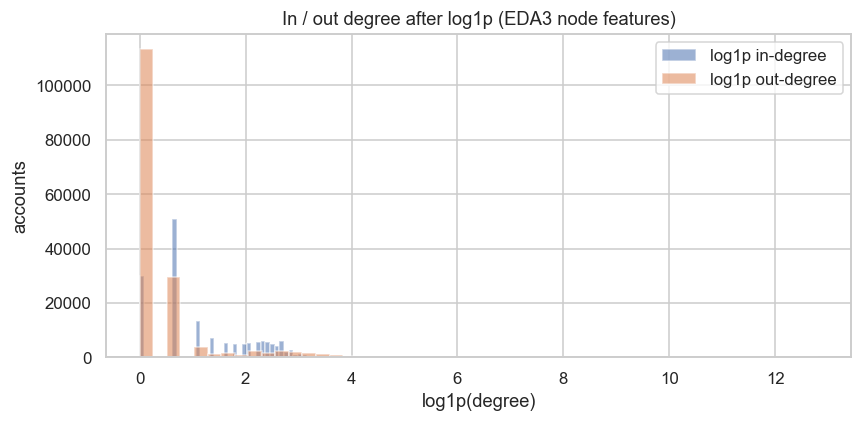

In [53]:
# --- graph size, self-loops, parallel edges, in/out degree (log1p is the EDA3 node feature) ---
pipe.section("6 Graph stats")
n_edges = df_sampled.height
n_nodes = accounts_frame(df_sampled).height
n_self = int(df_sampled["is_self_transfer"].sum())
n_pairs = pairs.height
print(f"nodes (accounts):     {n_nodes:,}    (HI-Medium has ~{KAGGLE_N_ACCOUNTS:,} globally)")
print(f"edges (transactions): {n_edges:,}")
print(f"density (simple):     {n_edges / max(n_nodes * (n_nodes - 1), 1):.6e}")
print(f"self-loops:           {n_self:,}  ({100*n_self/n_edges:.2f}%)")
print(f"unique directed pairs:{n_pairs:,}  → parallel extras: {n_edges - n_pairs:,}")
print(f"cross-bank edges:     {100*df_sampled['is_cross_bank'].mean():.2f}%")
print(f"cross-currency edges: {100*df_sampled['is_cross_currency'].mean():.2f}%")

# Account activity (the commented EDA.ipynb user-frequency analysis, turned on).
activity = node_deg["degree"]
print(f"\nAccounts with 1 tx:  {(activity == 1).sum():,} ({100*(activity == 1).mean():.2f}%)")
print(f"Accounts with 2 tx:  {(activity == 2).sum():,} ({100*(activity == 2).mean():.2f}%)")
print(f"Accounts with 3+ tx: {(activity >= 3).sum():,} ({100*(activity >= 3).mean():.2f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log1p(node_deg["in_degree"].to_numpy()), bins=50, alpha=0.55, label="log1p in-degree")
ax.hist(np.log1p(node_deg["out_degree"].to_numpy()), bins=50, alpha=0.55, label="log1p out-degree")
ax.set_title("In / out degree after log1p (EDA3 node features)")
ax.set_xlabel("log1p(degree)")
ax.set_ylabel("accounts")
ax.legend()
plt.tight_layout()
plt.show()


WCC find roots: 100%|██████████| 162756/162756 [00:00<00:00, 2471661.33node/s]


Weakly connected components: 30,098
  largest: 77,289 accounts
  median:  2
  mean:    5.4
  isolated-ish (size 1): 3,350
If laundering sits inside large components, 2–4 hop SAGE can reach the ring.


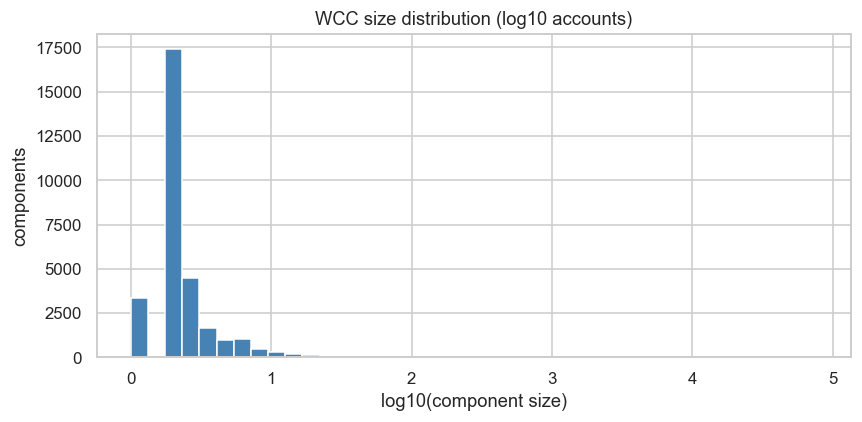

In [54]:
# --- weakly connected components on the subsample (union-find; NetworkX is slower at ~4M edges) ---
parent = {}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    parent.setdefault(a, a)
    parent.setdefault(b, b)
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

src_all = df_sampled["sender_id"].to_list()
dst_all = df_sampled["receiver_id"].to_list()
for s, d in tqdm(zip(src_all, dst_all), total=len(src_all), desc="WCC union-find", unit="edge"):
    union(s, d)

comp_size = Counter(find(x) for x in tqdm(parent, desc="WCC find roots", unit="node"))
sizes = np.array(list(comp_size.values()))
print(f"Weakly connected components: {len(sizes):,}")
print(f"  largest: {sizes.max():,} accounts")
print(f"  median:  {int(np.median(sizes)):,}")
print(f"  mean:    {sizes.mean():.1f}")
print(f"  isolated-ish (size 1): {(sizes == 1).sum():,}")
print("If laundering sits inside large components, 2–4 hop SAGE can reach the ring.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(sizes), bins=40, color="steelblue")
ax.set_title("WCC size distribution (log10 accounts)")
ax.set_xlabel("log10(component size)")
ax.set_ylabel("components")
plt.tight_layout()
plt.show()


In [55]:
# --- IBM 60/20/20 chronological split on the PRIMARY window only ---
# Do not put the all-laundering post-Nov-5 tail into test (Kaggle artifact).
primary = df_sampled.filter(
    (pl.col("ts") >= pl.lit(PRIMARY_START)) & (pl.col("ts") <= pl.lit(PRIMARY_END))
).sort("ts")
post_s = df_sampled.filter(pl.col("ts") > pl.lit(PRIMARY_END))
print(f"Primary-window rows in subsample: {primary.height:,}")
print(
    f"Post-window rows in subsample:    {post_s.height:,}  "
    f"laundering rate={float(post_s['Is Laundering'].mean()) if post_s.height else float('nan'):.2%}"
)

n = primary.height
n_train, n_val = int(round(n * 0.60)), int(round(n * 0.20))
n_test = n - n_train - n_val
idx_train = np.arange(0, n_train)
idx_val = np.arange(n_train, n_train + n_val)
idx_test = np.arange(n_train + n_val, n)
splits = {"train": idx_train, "val": idx_val, "test": idx_test}
y_primary = primary["Is Laundering"].to_numpy()
print("\nChronological 60/20/20 on primary window:")
for name, idx in splits.items():
    yy = y_primary[idx]
    print(f"  {name:5s}  n={len(yy):,}  laundering={int(yy.sum()):,}  rate={yy.mean():.4%}")

pos_weight = (y_primary[idx_train] == 0).sum() / max((y_primary[idx_train] == 1).sum(), 1)
print(f"\npos_weight (train, for BCEWithLogits): {pos_weight:.2f}   (≈19 when the mix is 5%)")
print("Do NOT use EDA3's random stratified split here — it leaks future rings into train.")


Primary-window rows in subsample: 700,483
Post-window rows in subsample:    4,117  laundering rate=99.20%

Chronological 60/20/20 on primary window:
  train  n=420,290  laundering=16,694  rate=3.9720%
  val    n=140,097  laundering=8,247  rate=5.8866%
  test   n=140,096  laundering=6,205  rate=4.4291%

pos_weight (train, for BCEWithLogits): 24.18   (≈19 when the mix is 5%)
Do NOT use EDA3's random stratified split here — it leaks future rings into train.


In [56]:
# --- feature recipe a GNN can take from this EDA ---
print("""GNN design notes from this EDA
================================
Task:        EDGE classification (Is Laundering on each transaction).
Graph:       directed MULTIGRAPH, accounts = nodes, transactions = edges.
Self-loops:  KEEP (Reinvestment / same-account transfers).
Banks:       do NOT one-hot (cardinality is huge). Use is_cross_bank instead.

Node features (EDA3):
    log1p(in_degree), log1p(out_degree)
    — in vs out matters because mules receive then send.

Edge features:
    RobustScaler(amount, hours_from_start) fit on TRAIN only, clip to [-10, 10]
    Payment Format one-hot (drop_first)
    is_cross_bank, is_cross_currency, is_self_transfer

Split: chronological 60/20/20 on Sep 1 – Sep 16 only.
Metric: AUPRC (accuracy is ~99.9% at the real 0.110% prior).
Loss:   BCE with pos_weight ≈ n_neg/n_pos on train (~19 at 5% positives).
Hops:   2–4 covers typical AMLSim rings; that is why we neighborhood-sample.
""")

format_dummies = df_sampled["Payment Format"].value_counts().sort("count", descending=True)
print("Payment Format levels to one-hot:")
print(format_dummies)
print(f"\nedge_attr dim ≈ 2 continuous + {format_dummies.height - 1} format dummies + 3 flags")


GNN design notes from this EDA
Task:        EDGE classification (Is Laundering on each transaction).
Graph:       directed MULTIGRAPH, accounts = nodes, transactions = edges.
Self-loops:  KEEP (Reinvestment / same-account transfers).
Banks:       do NOT one-hot (cardinality is huge). Use is_cross_bank instead.

Node features (EDA3):
    log1p(in_degree), log1p(out_degree)
    — in vs out matters because mules receive then send.

Edge features:
    RobustScaler(amount, hours_from_start) fit on TRAIN only, clip to [-10, 10]
    Payment Format one-hot (drop_first)
    is_cross_bank, is_cross_currency, is_self_transfer

Split: chronological 60/20/20 on Sep 1 – Sep 16 only.
Metric: AUPRC (accuracy is ~99.9% at the real 0.110% prior).
Loss:   BCE with pos_weight ≈ n_neg/n_pos on train (~19 at 5% positives).
Hops:   2–4 covers typical AMLSim rings; that is why we neighborhood-sample.

Payment Format levels to one-hot:
shape: (7, 2)
┌────────────────┬────────┐
│ Payment Format ┆ count  │
│ ---

## 7. Mule networks and topologies

IBM models placement → layering → integration. `HI-Medium_Patterns.txt` lists laundering that follows **8 AMLSim types**. Kaggle is explicit: **not all laundering is one of those 8**.

We (1) parse the official pattern file, then (2) measure rings in the **laundering-only** directed graph: component sizes, source / mule / sink roles, a simple topology label, and a couple of small drawings.


    stage done in 1.3s | running total 57.5s


EDA-IBM:  55%|█████▍    | 6/11 stages [00:57<00:30] , 7 Mule networks


[7/11 | 55%] 7 Mule networks
File: /Users/wesley/.cache/kagglehub/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/versions/8/HI-Medium_Patterns.txt
BEGIN LAUNDERING ATTEMPT headers: 2,756
Pattern-type hits (regex; a type name can appear more than once per attempt):
  FAN-OUT            1,035
  FAN-IN             1,387
  CYCLE              734
  BIPARTITE          738
  STACK              672
  RANDOM             662
  SCATTER-GATHER     662
  GATHER-SCATTER     644

--- file preview (first 1200 chars) ---
BEGIN LAUNDERING ATTEMPT - STACK
2022/09/01 05:14,00952,8139F54E0,0111632,8062C56E0,5331.44,US Dollar,5331.44,US Dollar,ACH,1
2022/09/03 13:09,0111632,8062C56E0,008456,81363F620,5602.59,US Dollar,5602.59,US Dollar,ACH,1
2022/09/01 07:40,0118693,823D5EB90,013729,801CF2E60,1400.54,US Dollar,1400.54,US Dollar,ACH,1
2022/09/01 14:19,013729,801CF2E60,0123621,81A7090F0,1467.94,US Dollar,1467.94,US Dollar,ACH,1
2022/09/02 12:40,0024750,81363F410,0213834,808757B00,16898.2

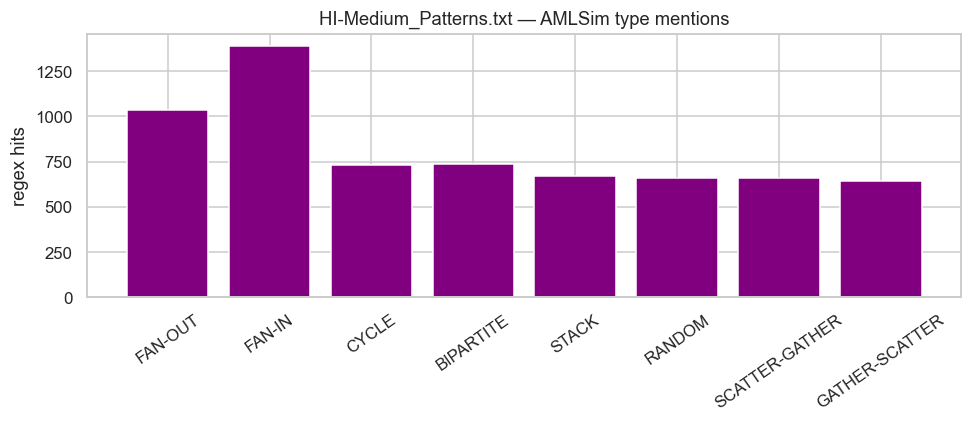

In [57]:
# --- parse HI-Medium_Patterns.txt for the 8 AMLSim types ---
pipe.section("7 Mule networks")
def parse_patterns(path: str):
    """Count pattern-instance headers. Format varies slightly; regex is more robust than a full parser."""
    raw = Path(path).read_text(errors="replace")
    n_begin = len(re.findall(r"BEGIN\s+LAUNDERING\s+ATTEMPT", raw, flags=re.I))
    counts = Counter()
    # 'PATTERN FAN-OUT' or 'FAN-OUT PATTERN' or bare 'FAN-OUT' near a BEGIN line.
    header_hits = re.findall(
        r"PATTERN\s+([A-Z][A-Z\- ]+)|\b("
        + "|".join(t.replace("-", "[- ]?") for t in AMLSIM_TYPES)
        + r")\b",
        raw,
        flags=re.I,
    )
    for a, b in header_hits:
        token = (a or b).strip().upper().replace(" ", "-")
        token = token.replace("FANOUT", "FAN-OUT").replace("FANIN", "FAN-IN")
        for t in AMLSIM_TYPES:
            if token.startswith(t) or t in token:
                counts[t] += 1
                break
    return raw, n_begin, counts


if os.path.isfile(PATTERNS_FILE):
    preview, n_begin, patt_counts = parse_patterns(PATTERNS_FILE)
    print(f"File: {PATTERNS_FILE}")
    print(f"BEGIN LAUNDERING ATTEMPT headers: {n_begin:,}")
    print("Pattern-type hits (regex; a type name can appear more than once per attempt):")
    for t in AMLSIM_TYPES:
        print(f"  {t:18s} {patt_counts.get(t, 0):,}")
    print("\n--- file preview (first 1200 chars) ---")
    print(preview[:1200])
    print("\nLaundering in HI-Medium:", f"{n_laundering:,}")
    print(
        "Pattern-listed attempts vs unlabeled laundering: the 8 types are a SUBSET "
        "(Kaggle: not all laundering follows them)."
    )

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(AMLSIM_TYPES, [patt_counts.get(t, 0) for t in AMLSIM_TYPES], color="purple")
    ax.set_title("HI-Medium_Patterns.txt — AMLSim type mentions")
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylabel("regex hits")
    plt.tight_layout()
    plt.show()
else:
    n_begin, patt_counts = 0, {}
    print("Patterns file not found — skipping official type counts.")


Laundering edges in subsample: 35,230


Measure rings: 100%|██████████| 11689/11689 [00:00<00:00, 19549.37ring/s]

Laundering rings (WCCs): 11,689
shape: (1, 6)
┌─────────┬─────────────────┬───────────────┬──────────────┬────────┬────────────┐
│ n_rings ┆ median_accounts ┆ mean_accounts ┆ max_accounts ┆ max_tx ┆ mean_mules │
│ ---     ┆ ---             ┆ ---           ┆ ---          ┆ ---    ┆ ---        │
│ u32     ┆ f64             ┆ f64           ┆ i64          ┆ i64    ┆ f64        │
╞═════════╪═════════════════╪═══════════════╪══════════════╪════════╪════════════╡
│ 11689   ┆ 2.0             ┆ 3.580888      ┆ 4552         ┆ 5104   ┆ 0.645393   │
└─────────┴─────────────────┴───────────────┴──────────────┴────────┴────────────┘

Rings by inferred topology:
shape: (8, 2)
┌────────────────┬──────┐
│ topology       ┆ len  │
│ ---            ┆ ---  │
│ str            ┆ u32  │
╞════════════════╪══════╡
│ bipartite      ┆ 8978 │
│ stack          ┆ 1892 │
│ cycle          ┆ 330  │
│ scatter-gather ┆ 136  │
│ gather-scatter ┆ 121  │
│ fan-in         ┆ 112  │
│ fan-out        ┆ 102  │
│ random         ┆

n_accounts,n_tx,n_source,n_mule,n_sink,total_aud,time_span_hours,max_in,max_out,pct_cross_bank,topology
i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,str
4552,5104,663,840,3049,1.3318e10,635.466667,24,1524,99.020376,"""scatter-gather"""
361,363,44,6,311,8.5808e8,585.133333,14,280,100.0,"""scatter-gather"""
341,345,8,24,309,3.7454e7,473.783333,2,164,100.0,"""scatter-gather"""
328,494,89,158,81,2.3906e9,539.7,18,19,98.380567,"""stack"""
193,196,2,2,189,1.9783e7,382.983333,3,193,100.0,"""scatter-gather"""
136,136,1,3,132,5.9971e6,379.9,2,133,100.0,"""scatter-gather"""
130,144,2,15,113,7.3858e6,512.7,15,114,100.0,"""scatter-gather"""
124,126,1,0,123,5.0338e6,379.9,2,126,100.0,"""fan-out"""
124,125,9,15,100,3.6198e6,471.466667,7,100,99.2,"""scatter-gather"""


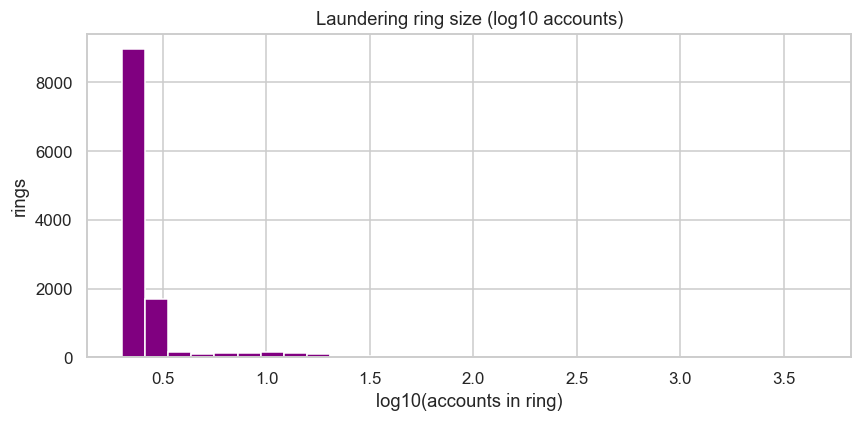

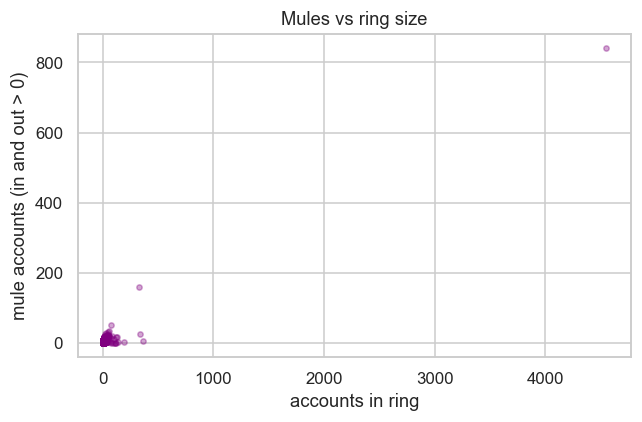

In [58]:
# --- laundering-only directed multigraph: rings = weakly connected components ---
launder = df_sampled.filter(pl.col("Is Laundering") == 1)
print(f"Laundering edges in subsample: {launder.height:,}")

# Build edge list once.
src_l = launder["sender_id"].to_list()
dst_l = launder["receiver_id"].to_list()
amt_l = launder["amount"].to_list()
ts_l = launder["ts"].to_list()
cross_bank_l = launder["is_cross_bank"].to_list()

parent_r = {}

def find_r(x):
    while parent_r[x] != x:
        parent_r[x] = parent_r[parent_r[x]]
        x = parent_r[x]
    return x

def union_r(a, b):
    parent_r.setdefault(a, a)
    parent_r.setdefault(b, b)
    ra, rb = find_r(a), find_r(b)
    if ra != rb:
        parent_r[rb] = ra

for s, d in tqdm(zip(src_l, dst_l), total=len(src_l), desc="Laundering WCC union-find", unit="edge"):
    union_r(s, d)

# Bucket edges by component root.
comp_edges = defaultdict(list)
for i, (s, d) in enumerate(tqdm(zip(src_l, dst_l), total=len(src_l), desc="Bucket ring edges", unit="edge")):
    comp_edges[find_r(s)].append(i)

rows = []
example_graphs = []  # small rings we can draw
for root, eidx in tqdm(comp_edges.items(), desc="Measure rings", unit="ring"):
    nodes = set()
    in_d, out_d = Counter(), Counter()
    total_amt = 0.0
    times = []
    n_xb = 0
    for i in eidx:
        s, d = src_l[i], dst_l[i]
        nodes.add(s)
        nodes.add(d)
        out_d[s] += 1
        in_d[d] += 1
        total_amt += float(amt_l[i] or 0)
        if ts_l[i] is not None:
            times.append(ts_l[i])
        n_xb += int(cross_bank_l[i])
    n_src = sum(1 for n in nodes if out_d[n] > 0 and in_d[n] == 0)
    n_sink = sum(1 for n in nodes if in_d[n] > 0 and out_d[n] == 0)
    n_mule = sum(1 for n in nodes if in_d[n] > 0 and out_d[n] > 0)
    n_iso = len(nodes) - n_src - n_sink - n_mule
    span_h = 0.0
    if len(times) >= 2:
        span_h = (max(times) - min(times)).total_seconds() / 3600.0

    # Topology heuristic using the 8 AMLSim names.
    has_cycle = False
    if len(nodes) <= 80:
        G = nx.DiGraph()
        G.add_edges_from((src_l[i], dst_l[i]) for i in eidx)
        has_cycle = (not nx.is_directed_acyclic_graph(G)) if G.number_of_edges() else False
        if 3 <= len(nodes) <= 40:
            example_graphs.append((len(nodes), G, n_src, n_sink, n_mule))

    if has_cycle:
        topo = "cycle"
    elif n_mule == 0:
        if n_src >= 3 * max(n_sink, 1):
            topo = "fan-in"
        elif n_sink >= 3 * max(n_src, 1):
            topo = "fan-out"
        else:
            topo = "bipartite"
    elif n_src > n_sink and n_src > n_mule:
        topo = "gather-scatter"
    elif n_sink > n_src and n_sink > n_mule:
        topo = "scatter-gather"
    elif n_mule >= max(n_src, n_sink, 1):
        topo = "stack"
    else:
        topo = "random"

    rows.append(
        {
            "n_accounts": len(nodes),
            "n_tx": len(eidx),
            "n_source": n_src,
            "n_mule": n_mule,
            "n_sink": n_sink,
            "total_aud": total_amt,
            "time_span_hours": span_h,
            "max_in": max(in_d.values()) if in_d else 0,
            "max_out": max(out_d.values()) if out_d else 0,
            "pct_cross_bank": 100 * n_xb / max(len(eidx), 1),
            "topology": topo,
        }
    )

rings = pl.DataFrame(rows)
print(f"Laundering rings (WCCs): {rings.height:,}")
print(
    rings.select(
        pl.len().alias("n_rings"),
        pl.col("n_accounts").median().alias("median_accounts"),
        pl.col("n_accounts").mean().alias("mean_accounts"),
        pl.col("n_accounts").max().alias("max_accounts"),
        pl.col("n_tx").max().alias("max_tx"),
        pl.col("n_mule").mean().alias("mean_mules"),
    )
)
print("\nRings by inferred topology:")
print(rings.group_by("topology").len().sort("len", descending=True))

print("\n10 largest rings:")
display(rings.sort("n_accounts", descending=True).head(10))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(np.clip(rings["n_accounts"].to_numpy(), 1, None)), bins=30, color="purple")
ax.set_title("Laundering ring size (log10 accounts)")
ax.set_xlabel("log10(accounts in ring)")
ax.set_ylabel("rings")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(rings["n_accounts"].to_numpy(), rings["n_mule"].to_numpy(), alpha=0.35, s=12, color="purple")
ax.set_title("Mules vs ring size")
ax.set_xlabel("accounts in ring")
ax.set_ylabel("mule accounts (in and out > 0)")
plt.tight_layout()
plt.show()


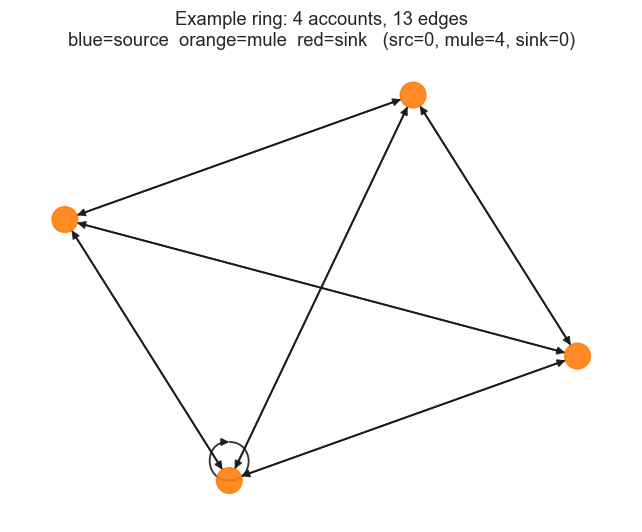

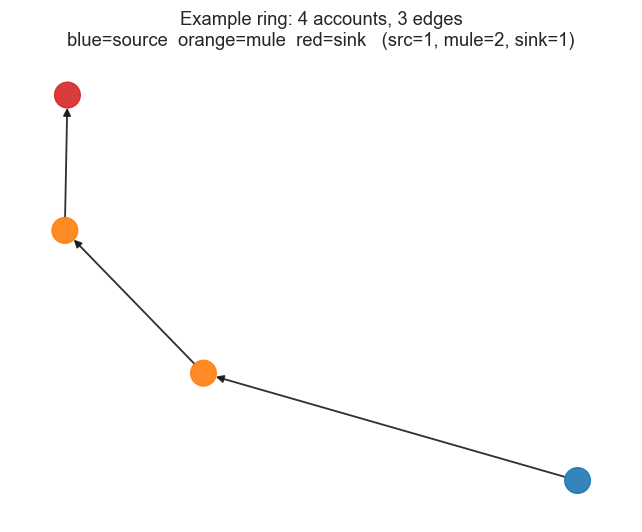

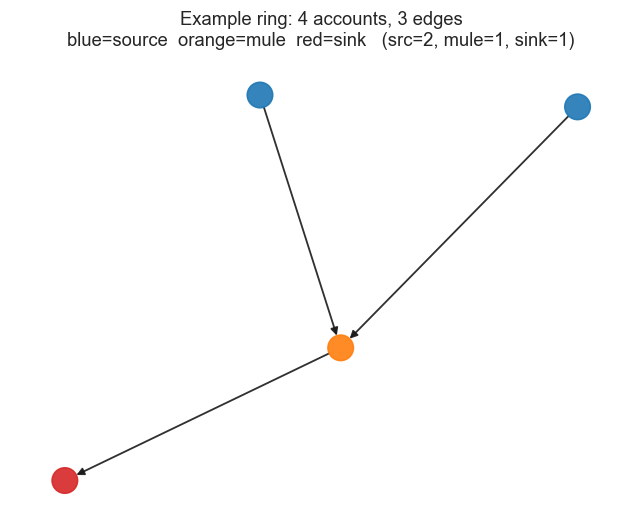

In [59]:
# --- draw 2–3 small example rings (never the full 4M-edge graph) ---
example_graphs = sorted(example_graphs, key=lambda t: t[0])
drawn = 0
for n_acc, G, n_src, n_sink, n_mule in example_graphs:
    if drawn >= 3:
        break
    if G.number_of_nodes() < 4:
        continue
    color = []
    for node in G.nodes():
        inn, outn = G.in_degree(node), G.out_degree(node)
        if outn > 0 and inn == 0:
            color.append("#1f77b4")  # source
        elif inn > 0 and outn == 0:
            color.append("#d62728")  # sink
        else:
            color.append("#ff7f0e")  # mule
    fig, ax = plt.subplots(figsize=(6, 5))
    pos = nx.spring_layout(G, seed=RANDOM_STATE)
    nx.draw_networkx(
        G, pos=pos, ax=ax, node_color=color, node_size=280,
        with_labels=False, arrows=True, width=1.2, alpha=0.9,
    )
    ax.set_title(
        f"Example ring: {G.number_of_nodes()} accounts, {G.number_of_edges()} edges\n"
        f"blue=source  orange=mule  red=sink   (src={n_src}, mule={n_mule}, sink={n_sink})"
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    drawn += 1
if drawn == 0:
    print("No small (4–40 node) rings to draw — components may all be tiny pairs or huge.")


In [60]:
# --- 1-hop legit camouflage around rings + cross-bank share ---
# Why neighborhood negatives belong in the subsample: mules also send ordinary payments.
ring_accounts = accounts_frame(launder).get_column("account")
camo = df_sampled.filter(
    (pl.col("Is Laundering") == 0)
    & (pl.col("sender_id").is_in(ring_accounts) | pl.col("receiver_id").is_in(ring_accounts))
)
print(f"Legit edges that touch a laundering-ring account (1-hop camouflage): {camo.height:,}")
print(f"That's {100*camo.height/max(df_sampled.height,1):.2f}% of the subsample.")

xb_all = float(launder["is_cross_bank"].mean())
print(f"\nShare of laundering edges that are CROSS-BANK: {xb_all:.2%}")
print("A single-bank model never sees those counterparties (Kaggle writeup).")
print(f"Official pattern attempts parsed: {n_begin:,}. Unlabeled laundering still exists beyond the 8 types.")


Legit edges that touch a laundering-ring account (1-hop camouflage): 411,450
That's 58.39% of the subsample.

Share of laundering edges that are CROSS-BANK: 99.03%
A single-bank model never sees those counterparties (Kaggle writeup).
Official pattern attempts parsed: 2,756. Unlabeled laundering still exists beyond the 8 types.


/var/folders/85/tw01mlpj2652rq0cxftdtsvw0000gn/T/ipykernel_46170/1546885495.py:4: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  camo = df_sampled.filter(


## Takeaways for the GNN

1. **Prior vs train mix.** Full-file laundering is **~0.110%** (1 in 905). The subsample targets **5%** via `round(n_fraud / 0.05)` (~700K on HI-Medium). We only pad to 750K if that still keeps ≥ 5%.
2. **Task.** Edge classification on a directed multigraph. Keep self-loops. Do not one-hot banks.
3. **Features.** Node: `log1p(in_degree)`, `log1p(out_degree)`. Edge: scaled `amount` + `hours_from_start`, Payment Format dummies, `is_cross_bank`, `is_cross_currency`, `is_self_transfer`.
4. **Split.** Chronological **60/20/20** on **1 Sep – 16 Sep 2022** only. The post-window tail is all laundering — do not use it as test.
5. **Metric / loss.** AUPRC; `pos_weight ≈ 19` at a 5% mix.
6. **Why a GNN.** Laundering is rings (fan-in, fan-out, cycle, gather-scatter, …), not isolated rows. 2–4 hops covers typical AMLSim patterns; neighborhood legit is camouflage, not noise to throw away.
7. **Patterns file.** The 8 AMLSim types are a labeled subset. Size rings from the laundering WCC regardless.
8. **GNN.** Sections 8–11 run `prepare_gnn_data()` (train-only scaler / dummies / degrees) then GraphSAGE edge classification. Set `FAST_MODE = False` for Optuna.

Cached subsample: `ibm_hi_medium_sample.parquet`. Cached graph tensors: `ibm_hi_medium_graph.pt`.


## 8. Feature engineering → GNN tensors

One function, `prepare_gnn_data`, takes the subsample (or any similarly shaped table) and the feature lists chosen in the EDA. It does **all** graph construction with no leakage:

- drop the post-window all-laundering tail
- chronological 60/20/20 split (IBM recommendation)
- `RobustScaler` fit on **train only**
- Payment Format one-hot levels fit on **train only** (`handle_unknown=ignore`)
- node `log1p` in/out degree from **train edges only**
- rolling subgraphs: train = past; val scores the present slice of past+present; test scores the future slice of the full graph

The returned `GraphPack` is what the GNN consumes.


In [61]:
# --- prepare_gnn_data: subsample DataFrame -> leak-free GraphPack ---
from dataclasses import dataclass

import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import f1_score
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import degree

pipe.section("8 Prepare GNN tensors")


def pick_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


@dataclass
class GraphPack:
    """Everything the GNN needs, aligned on the same edge order."""
    df: object
    edge_index: object
    edge_attr: object
    edge_labels: object
    train_mask: object
    val_mask: object
    test_mask: object
    node_features: object
    train_edge_index: object
    train_edge_attr: object
    train_labels: object
    val_edge_index: object
    val_edge_attr: object
    val_labels: object
    num_val_edges: int
    num_test_edges: int
    pos_weight: float
    feature_names: list
    num_nodes: int
    scaler: object
    cat_encoder: object


def prepare_gnn_data(
    df,
    src_col="sender_id",
    dst_col="receiver_id",
    label_col="Is Laundering",
    time_col="ts",
    cont_cols=None,
    cat_cols=None,
    bin_cols=None,
    split=(0.60, 0.20, 0.20),
    primary_start=None,
    primary_end=None,
    clip=10.0,
):
    """Turn a transaction table into graph tensors.

    Pass whatever feature lists the EDA chose via cont_cols / cat_cols / bin_cols.
    Scaler, one-hot levels, and node degrees are fit on TRAIN edges only.
    """
    if cont_cols is None:
        cont_cols = ["amount", "hours_from_start"]
    if cat_cols is None:
        cat_cols = ["Payment Format"]
    if bin_cols is None:
        bin_cols = ["is_self_transfer", "is_cross_bank", "is_cross_currency"]
    if primary_start is None:
        primary_start = PRIMARY_START
    if primary_end is None:
        primary_end = PRIMARY_END

    # hours_from_start is rebuilt after the window filter, so it need not exist yet.
    needed = [src_col, dst_col, label_col, time_col]
    needed += [c for c in cont_cols if c != "hours_from_start"]
    needed += list(cat_cols) + list(bin_cols)
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise KeyError("prepare_gnn_data missing columns: " + ", ".join(missing))

    # 1. Primary window only (post-window tail is 100% laundering).
    work = df.filter(
        (pl.col(time_col) >= pl.lit(primary_start)) & (pl.col(time_col) <= pl.lit(primary_end))
    )
    if work.height == 0:
        raise ValueError("No rows left after applying the primary time window.")

    # 2. Chronological order + time feature relative to this window.
    work = work.sort(time_col).with_row_index("_row_ord")
    t0 = work[time_col].min()
    work = work.with_columns(
        ((pl.col(time_col) - t0).dt.total_seconds() / 3600.0).alias("hours_from_start")
    )

    n = work.height
    n_train = int(round(n * split[0]))
    n_val = int(round(n * split[1]))
    n_test = n - n_train - n_val
    idx_train = np.arange(0, n_train)
    idx_val = np.arange(n_train, n_train + n_val)
    idx_test = np.arange(n_train + n_val, n)

    y = work[label_col].cast(pl.Int8).to_numpy()
    print(
        f"Primary-window edges: {n:,} | train {n_train:,} | val {n_val:,} | test {n_test:,}"
    )
    for name, idx in (("train", idx_train), ("val", idx_val), ("test", idx_test)):
        print(f"  {name:5s} laundering={int(y[idx].sum()):,}  rate={y[idx].mean():.4%}")

    # 3. Continuous features: scaler fit on train only, then clip.
    X_cont = work.select(list(cont_cols)).cast(pl.Float64).to_numpy()
    scaler = RobustScaler()
    X_cont_scaled = X_cont.copy()
    X_cont_scaled[idx_train] = scaler.fit_transform(X_cont[idx_train])
    X_cont_scaled[idx_val] = scaler.transform(X_cont[idx_val])
    X_cont_scaled[idx_test] = scaler.transform(X_cont[idx_test])
    X_cont_scaled = np.clip(X_cont_scaled, -clip, clip)

    # 4. Categorical: one-hot levels from train; unknown future formats -> zeros.
    cat_encoder = None
    cat_names = []
    X_cat = np.zeros((n, 0), dtype=np.float32)
    if cat_cols:
        X_cat_raw = work.select(list(cat_cols)).cast(pl.Utf8).to_numpy()
        try:
            cat_encoder = OneHotEncoder(
                drop="first", handle_unknown="ignore", sparse_output=False
            )
        except TypeError:
            cat_encoder = OneHotEncoder(
                drop="first", handle_unknown="ignore", sparse=False
            )
        if X_cat_raw.ndim == 1:
            X_cat_raw = X_cat_raw.reshape(-1, 1)
        cat_encoder.fit(X_cat_raw[idx_train])
        X_cat = cat_encoder.transform(X_cat_raw).astype(np.float32)
        cat_names = list(cat_encoder.get_feature_names_out(list(cat_cols)))

    # 5. Binary flags already 0/1 from EDA cleaning.
    X_bin = work.select(list(bin_cols)).cast(pl.Float32).to_numpy() if bin_cols else np.zeros((n, 0), dtype=np.float32)

    edge_features = np.hstack([X_cont_scaled.astype(np.float32), X_cat, X_bin])
    feature_names = list(cont_cols) + cat_names + list(bin_cols)

    # 6. Account strings -> integer node ids.
    src_names = work[src_col].to_numpy()
    dst_names = work[dst_col].to_numpy()
    all_nodes = np.unique(np.concatenate([src_names, dst_names]))
    nodes_df = pl.DataFrame({"name": all_nodes}).with_row_index("node_id")
    work = (
        work.join(nodes_df, left_on=src_col, right_on="name", how="left")
        .rename({"node_id": "src_id"})
        .join(nodes_df, left_on=dst_col, right_on="name", how="left")
        .rename({"node_id": "dst_id"})
        .sort("_row_ord")
        .drop("_row_ord")
    )
    src = work["src_id"].to_numpy()
    dst = work["dst_id"].to_numpy()
    num_nodes = len(all_nodes)

    edge_index = torch.tensor(np.vstack([src, dst]), dtype=torch.long)
    edge_attr = torch.tensor(edge_features, dtype=torch.float)
    edge_labels = torch.tensor(y, dtype=torch.float)

    train_mask = torch.zeros(n, dtype=torch.bool)
    val_mask = torch.zeros(n, dtype=torch.bool)
    test_mask = torch.zeros(n, dtype=torch.bool)
    train_mask[idx_train] = True
    val_mask[idx_val] = True
    test_mask[idx_test] = True

    pos_weight = float((y[idx_train] == 0).sum() / max((y[idx_train] == 1).sum(), 1))

    # 7. Node features: log1p in/out degree on TRAIN edges only (no future leak).
    train_edge_index = edge_index[:, train_mask]
    out_deg = torch.log1p(degree(train_edge_index[0], num_nodes=num_nodes, dtype=torch.float))
    in_deg = torch.log1p(degree(train_edge_index[1], num_nodes=num_nodes, dtype=torch.float))
    node_features = torch.stack([in_deg, out_deg], dim=1)

    # 8. Rolling time subgraphs (copy-2 pattern).
    train_edge_attr = edge_attr[train_mask]
    train_labels = edge_labels[train_mask]
    val_subgraph_mask = train_mask | val_mask
    val_edge_index = edge_index[:, val_subgraph_mask]
    val_edge_attr = edge_attr[val_subgraph_mask]
    val_labels = edge_labels[val_mask]

    pack = GraphPack(
        df=work,
        edge_index=edge_index,
        edge_attr=edge_attr,
        edge_labels=edge_labels,
        train_mask=train_mask,
        val_mask=val_mask,
        test_mask=test_mask,
        node_features=node_features,
        train_edge_index=train_edge_index,
        train_edge_attr=train_edge_attr,
        train_labels=train_labels,
        val_edge_index=val_edge_index,
        val_edge_attr=val_edge_attr,
        val_labels=val_labels,
        num_val_edges=int(val_mask.sum()),
        num_test_edges=int(test_mask.sum()),
        pos_weight=pos_weight,
        feature_names=feature_names,
        num_nodes=num_nodes,
        scaler=scaler,
        cat_encoder=cat_encoder,
    )
    print(f"nodes={num_nodes:,} | edges={n:,} | edge_attr_dim={edge_attr.shape[1]}")
    print("feature_names:", feature_names)
    print(f"pos_weight (train): {pos_weight:.2f}")
    return pack


# Swap these lists if the EDA suggests a different recipe.
CONT_COLS = ["amount", "hours_from_start"]
CAT_COLS = ["Payment Format"]
BIN_COLS = ["is_self_transfer", "is_cross_bank", "is_cross_currency"]

pack = prepare_gnn_data(
    df_sampled,
    src_col="sender_id",
    dst_col="receiver_id",
    label_col="Is Laundering",
    time_col="ts",
    cont_cols=CONT_COLS,
    cat_cols=CAT_COLS,
    bin_cols=BIN_COLS,
    split=(0.60, 0.20, 0.20),
    primary_start=PRIMARY_START,
    primary_end=PRIMARY_END,
)

torch.save(
    {
        "edge_index": pack.edge_index,
        "edge_attr": pack.edge_attr,
        "edge_labels": pack.edge_labels,
        "train_mask": pack.train_mask,
        "val_mask": pack.val_mask,
        "test_mask": pack.test_mask,
        "node_features": pack.node_features,
        "pos_weight": pack.pos_weight,
        "feature_names": pack.feature_names,
        "num_nodes": pack.num_nodes,
    },
    GRAPH_PATH,
)
print(f"Wrote {GRAPH_PATH.resolve()}")


    stage done in 1.3s | running total 58.8s


EDA-IBM:  64%|██████▎   | 7/11 stages [00:58<00:18] , 8 Prepare GNN tensors


[8/11 | 64%] 8 Prepare GNN tensors
Primary-window edges: 700,483 | train 420,290 | val 140,097 | test 140,096
  train laundering=16,694  rate=3.9720%
  val   laundering=8,247  rate=5.8866%
  test  laundering=6,205  rate=4.4291%
nodes=159,774 | edges=700,483 | edge_attr_dim=11
feature_names: ['amount', 'hours_from_start', 'Payment Format_Bitcoin', 'Payment Format_Cash', 'Payment Format_Cheque', 'Payment Format_Credit Card', 'Payment Format_Reinvestment', 'Payment Format_Wire', 'is_self_transfer', 'is_cross_bank', 'is_cross_currency']
pos_weight (train): 24.18
Wrote /Users/wesley/Desktop/Capstone dataset/ibm_hi_medium_graph.pt


## 9. GNN definition (edge classification, no leak)

GraphSAGE on accounts, then an MLP on `[h_sender, h_receiver, edge_attr]` to score each transaction. Dropout uses the constructor argument (copy 2 hardcoded 0.2 while Optuna tuned dropout).


In [62]:
# --- MuleHunterGNN + move tensors onto the best available device ---
pipe.section("9 Define GNN")

device = pick_device()
print("device:", device) 


class MuleHunterGNN(nn.Module):
    """Inductive edge classifier: SAGE on nodes, MLP on (src, dst, edge)."""

    def __init__(self, node_in_dim, edge_attr_dim, hidden_dim=64, dropout=0.2):
        super().__init__()
        self.dropout_p = dropout
        self.node_proj = nn.Linear(node_in_dim, hidden_dim)
        self.conv1 = SAGEConv(hidden_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.predictor = nn.Sequential(
            nn.Linear(hidden_dim * 2 + edge_attr_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 1),
        )

    def forward(self, x, edge_index, edge_attr):
        x = self.node_proj(x)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout_p, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        edge_input = torch.cat([x[edge_index[0]], x[edge_index[1]], edge_attr], dim=-1)
        return self.predictor(edge_input).squeeze(-1)

    @torch.no_grad()
    def inference(self, x, edge_index, edge_attr):
        self.eval()
        probs = torch.sigmoid(self.forward(x, edge_index, edge_attr))
        return probs, probs.max()


def to_device(pack, device):
    """Move graph tensors; keep the Polars table on CPU."""
    tensor_fields = [
        "edge_index", "edge_attr", "edge_labels",
        "train_mask", "val_mask", "test_mask", "node_features",
        "train_edge_index", "train_edge_attr", "train_labels",
        "val_edge_index", "val_edge_attr", "val_labels",
    ]
    for name in tensor_fields:
        setattr(pack, name, getattr(pack, name).to(device))
    return pack


pack = to_device(pack, device)
print(
    f"GNN input: node_dim={pack.node_features.shape[1]}  "
    f"edge_dim={pack.edge_attr.shape[1]}  "
    f"train_edges={int(pack.train_mask.sum()):,}"
)


    stage done in 1.3s | running total 60.0s


EDA-IBM:  73%|███████▎  | 8/11 stages [01:00<00:11] , 9 Define GNN         


[9/11 | 73%] 9 Define GNN
device: mps
GNN input: node_dim=2  edge_dim=11  train_edges=420,290


## 10. Train (Optuna or FAST_MODE)

`FAST_MODE=True` (set in the setup cell) skips the search and trains a short run with copy-2-ish defaults. Set it to `False` for ~12 Optuna trials (maximize val AUPRC) then a 100-epoch final fit with early stopping.


    stage done in 1.9s | running total 62.0s


EDA-IBM:  82%|████████▏ | 9/11 stages [01:01<00:06] , 10 Train GNN


[10/11 | 82%] 10 Train GNN
FAST_MODE=True — skipping Optuna. Using copy-2-style defaults.
Training with: {'lr': 0.0008273940352041027, 'weight_decay': 1.2538998392757027e-05, 'hidden_dim': 128, 'dropout': 0.25846462661042013, 'pos_weight_factor': 1.1137601552842316}


Train GNN:  85%|████████▌ | 34/40 [01:06<00:11,  1.95s/epoch, loss=0.549 valAUPRC=0.850]

Early stopping at epoch 35 (best val AUPRC 0.8505)
Best val AUPRC: 0.8505


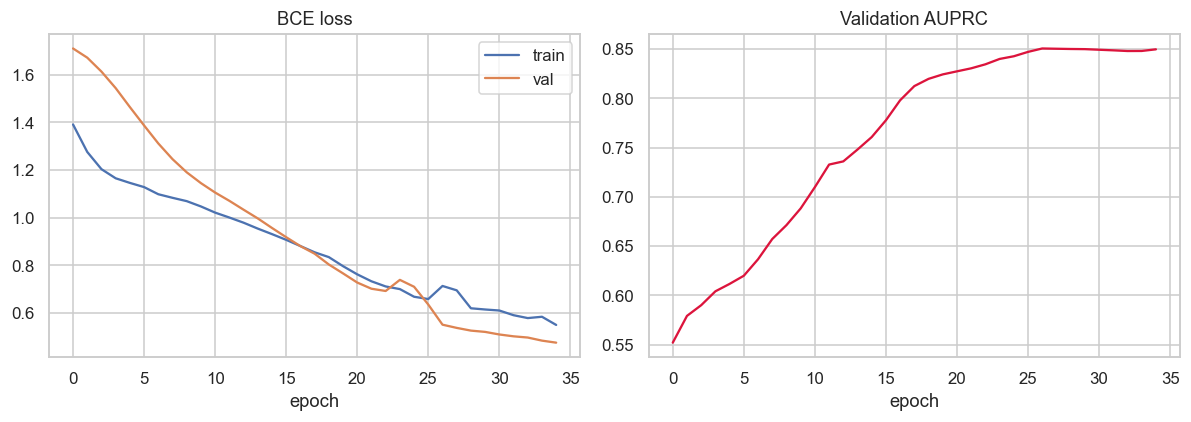

In [63]:
# --- Optuna search (optional) + final train with early stopping ---
pipe.section("10 Train GNN")


# Copy-2 Optuna winner (PaySim); used when FAST_MODE skips the search.
DEFAULT_PARAMS = {
    "lr": 0.0008273940352041027,
    "weight_decay": 1.2538998392757027e-05,
    "hidden_dim": 128,
    "dropout": 0.25846462661042013,
    "pos_weight_factor": 1.1137601552842316,
}


def eval_val_auprc(model, pack, criterion=None):
    model.eval()
    with torch.no_grad():
        hist_logits = model(pack.node_features, pack.val_edge_index, pack.val_edge_attr)
        val_logits = hist_logits[-pack.num_val_edges:]
        val_prob = torch.sigmoid(val_logits).detach().cpu().numpy()
        val_true = pack.val_labels.detach().cpu().numpy()
        auprc = average_precision_score(val_true, val_prob)
        loss = None
        if criterion is not None:
            loss = criterion(val_logits, pack.val_labels).item()
    return auprc, loss


def run_optuna(pack, n_trials=12, epochs=40):
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def objective(trial):
        params = {
            "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
            "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True),
            "hidden_dim": trial.suggest_categorical("hidden_dim", [32, 64, 128]),
            "dropout": trial.suggest_float("dropout", 0.1, 0.5),
            "pos_weight_factor": trial.suggest_float("pos_weight_factor", 0.8, 1.2),
        }
        model = MuleHunterGNN(
            node_in_dim=pack.node_features.shape[1],
            edge_attr_dim=pack.edge_attr.shape[1],
            hidden_dim=params["hidden_dim"],
            dropout=params["dropout"],
        ).to(device)
        opt = optim.Adam(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
        crit = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor([pack.pos_weight * params["pos_weight_factor"]], device=device)
        )
        best = 0.0
        for epoch in range(1, epochs + 1):
            model.train()
            opt.zero_grad()
            logits = model(pack.node_features, pack.train_edge_index, pack.train_edge_attr)
            loss = crit(logits, pack.train_labels)
            loss.backward()
            opt.step()
            if epoch % 5 == 0:
                auprc, _ = eval_val_auprc(model, pack)
                best = max(best, auprc)
                trial.report(auprc, epoch)
                if trial.should_prune():
                    raise optuna.exceptions.TrialPruned()
        return best

    study = optuna.create_study(
        direction="maximize",
        pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=10),
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    print(f"Best val AUPRC: {study.best_value:.4f}")
    print("Best params:", study.best_params)
    return study.best_params


if FAST_MODE:
    print("FAST_MODE=True — skipping Optuna. Using copy-2-style defaults.")
    best_params = dict(DEFAULT_PARAMS)
else:
    print("FAST_MODE=False — Optuna search (12 trials x 40 epochs).")
    best_params = run_optuna(pack, n_trials=12, epochs=40)

print("Training with:", best_params)

model = MuleHunterGNN(
    node_in_dim=pack.node_features.shape[1],
    edge_attr_dim=pack.edge_attr.shape[1],
    hidden_dim=int(best_params["hidden_dim"]),
    dropout=best_params["dropout"],
).to(device)
optimizer = optim.Adam(
    model.parameters(), lr=best_params["lr"], weight_decay=best_params["weight_decay"]
)
criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([pack.pos_weight * best_params["pos_weight_factor"]], device=device)
)

epochs = 40 if FAST_MODE else 100
patience = 8 if FAST_MODE else 15
history = {"train_loss": [], "val_loss": [], "val_auprc": []}
best_val = -1.0
best_state = None
stale = 0

epoch_bar = tqdm(range(1, epochs + 1), desc="Train GNN", unit="epoch")
for epoch in epoch_bar:
    model.train()
    optimizer.zero_grad()
    logits = model(pack.node_features, pack.train_edge_index, pack.train_edge_attr)
    loss = criterion(logits, pack.train_labels)
    loss.backward()
    optimizer.step()

    val_auprc, val_loss = eval_val_auprc(model, pack, criterion)
    history["train_loss"].append(loss.item())
    history["val_loss"].append(val_loss)
    history["val_auprc"].append(val_auprc)
    epoch_bar.set_postfix_str(f"loss={loss.item():.3f} valAUPRC={val_auprc:.3f}")

    if val_auprc > best_val:
        best_val = val_auprc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        stale = 0
    else:
        stale += 1
        if stale >= patience:
            print(f"Early stopping at epoch {epoch} (best val AUPRC {best_val:.4f})")
            break

if best_state is not None:
    model.load_state_dict(best_state)
    model.to(device)

print(f"Best val AUPRC: {best_val:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("BCE loss")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(history["val_auprc"], color="crimson")
axes[1].set_title("Validation AUPRC")
axes[1].set_xlabel("epoch")
plt.tight_layout()
plt.show()


## 11. Out-of-time test

Score the **future** slice only (last 20% of the primary window). JSON export is the top/bottom 5 test edges — not the whole test set.


In [64]:
# --- future-slice metrics + small JSON payload ---
pipe.section("11 Out-of-time test")

model.eval()
with torch.no_grad():
    full_logits = model(pack.node_features, pack.edge_index, pack.edge_attr)
    test_logits = full_logits[-pack.num_test_edges:]
    test_prob = torch.sigmoid(test_logits).detach().cpu().numpy()
    test_true = pack.edge_labels[pack.test_mask].detach().cpu().numpy()
    test_loss = criterion(test_logits, pack.edge_labels[pack.test_mask]).item()

test_auprc = average_precision_score(test_true, test_prob)
test_bin = (test_prob >= 0.50).astype(int)
prec = precision_score(test_true, test_bin, zero_division=0)
rec = recall_score(test_true, test_bin, zero_division=0)
f1 = f1_score(test_true, test_bin, zero_division=0)
base_rate = float(test_true.mean())

print("=" * 54)
print(" OUT-OF-TIME TEST (future edges only)")
print("=" * 54)
print(f"  n_test:     {len(test_true):,}")
print(f"  base rate:  {base_rate:.4%}   (AUPRC of a dummy ≈ this)")
print(f"  Test Loss:  {test_loss:.4f}")
print(f"  Test AUPRC: {test_auprc:.4f}")
print(f"  Precision:  {prec:.4f}")
print(f"  Recall:     {rec:.4f}")
print(f"  F1:         {f1:.4f}")
print("=" * 54)

test_mask_np = pack.test_mask.detach().cpu().numpy()
test_df = (
    pack.df.with_columns(pl.Series("_is_test", test_mask_np))
    .filter(pl.col("_is_test"))
    .drop("_is_test")
    .with_columns(pl.Series("risk_score", test_prob.astype(np.float64)))
)


def generate_graph_payload(df_subset, graph_id="sample"):
    """Small topology payload for a UI — never dump the full test graph."""
    n_nodes = pl.concat([df_subset["sender_id"], df_subset["receiver_id"]]).n_unique()
    n_edges = df_subset.height
    payload = {
        "graph_id": graph_id,
        "topology_metrics": {
            "node_count": int(n_nodes),
            "edge_count": int(n_edges),
            "density": round(n_edges / (n_nodes * (n_nodes - 1)), 6) if n_nodes > 1 else 0.0,
        },
        "edges": [],
    }
    for row in df_subset.iter_rows(named=True):
        score = float(row["risk_score"])
        if score > 0.90:
            risk_label = "CRITICAL"
        elif score > 0.75:
            risk_label = "HIGH"
        elif score > 0.50:
            risk_label = "MEDIUM"
        else:
            risk_label = "LOW"
        payload["edges"].append(
            {
                "source_node": row["sender_id"],
                "destination_node": row["receiver_id"],
                "edge_features": {
                    "amount": float(row["amount"]),
                    "payment_format": str(row["Payment Format"]),
                    "hours_from_start": float(row["hours_from_start"]),
                    "is_cross_bank": int(row["is_cross_bank"]),
                    "is_cross_currency": int(row["is_cross_currency"]),
                    "is_self_transfer": int(row["is_self_transfer"]),
                },
                "true_label": int(row["Is Laundering"]),
                "fraud_risk_score": round(score, 4),
                "risk_label": risk_label,
            }
        )
    return json.dumps(payload, indent=2)


print("\nHighest-risk test edges:")
print(generate_graph_payload(test_df.sort("risk_score", descending=True).head(5), "highest_risk_test_edges"))
print("\nLowest-risk test edges:")
print(generate_graph_payload(test_df.sort("risk_score", descending=False).head(5), "lowest_risk_test_edges"))

print(f"\nGraph tensors cached at {GRAPH_PATH.resolve()}")
pipe.finish()


    stage done in 66.5s | running total 128.5s


EDA-IBM:  91%|█████████ | 10/11 stages [02:08<00:21] , 11 Out-of-time test


[11/11 | 91%] 11 Out-of-time test
 OUT-OF-TIME TEST (future edges only)
  n_test:     140,096
  base rate:  4.4291%   (AUPRC of a dummy ≈ this)
  Test Loss:  0.5729
  Test AUPRC: 0.7780
  Precision:  0.2872
  Recall:     0.9417
  F1:         0.4402

Highest-risk test edges:
{
  "graph_id": "highest_risk_test_edges",
  "topology_metrics": {
    "node_count": 7,
    "edge_count": 5,
    "density": 0.119048
  },
  "edges": [
    {
      "source_node": "82601E630_281653",
      "destination_node": "82A186F80_112690",
      "edge_features": {
        "amount": 31874.4375,
        "payment_format": "ACH",
        "hours_from_start": 347.3833333333333,
        "is_cross_bank": 1,
        "is_cross_currency": 0,
        "is_self_transfer": 0
      },
      "true_label": 1,
      "fraud_risk_score": 0.9924,
      "risk_label": "CRITICAL"
    },
    {
      "source_node": "81494D550_152604",
      "destination_node": "8231A2590_10",
      "edge_features": {
        "amount": 28424.16,
        "

EDA-IBM: 100%|██████████| 11/11 stages [02:09<00:00] , done               


EDA-IBM complete in 129.5s
